# Bloque 1: #
Importa las librerías esenciales (pandas, pathlib, gc) y establece la estructura del sistema de archivos. Configura automáticamente las rutas del directorio de trabajo, la carpeta de entrada con los archivos CSV (matriculaaaas) y crea el directorio de salida (resultados_parquet) si aún no existe.

In [7]:
import gc
from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()
CARPETA_CSV = BASE_DIR / "matriculaaaas"
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"

CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

print(f"Directorio de trabajo: {BASE_DIR}")
print(f"Buscando archivos CSV en: {CARPETA_CSV}")
print(f"Guardando resúmenes Parquet en: {CARPETA_SALIDA}")

Directorio de trabajo: /home/leandro/Escritorio/Carreras
Buscando archivos CSV en: /home/leandro/Escritorio/Carreras/matriculaaaas
Guardando resúmenes Parquet en: /home/leandro/Escritorio/Carreras/resultados_parquet


# Bloque 2: #
Define la función procesar_anio, encargada del ETL individual. Carga el CSV anual, filtra registros de Universidades y nivel de Pregrado, detecta e imputa valores nulos o códigos especiales de ingreso (1900, 9995, etc.), audita la presencia de identificadores únicos (MRUN), evalúa inconsistencias en aranceles o duraciones y exporta el resultado consolidado por programa en formato Parquet comprimido.

In [8]:
def procesar_anio(
    ruta_csv, anio, carpeta_salida=CARPETA_SALIDA, encoding="utf-8"
):
  ruta_csv = Path(ruta_csv)
  salida = Path(carpeta_salida) / f"resumen_{anio}_provisional.parquet"

  if not ruta_csv.is_file():
    raise FileNotFoundError(f"No se encontró el CSV: {ruta_csv}")

  # 1. Cargar archivo preservando formatos originales
  datos = pd.read_csv(ruta_csv, sep=";", encoding=encoding, dtype="string")
  datos.columns = datos.columns.str.strip().str.lower()

  if datos.columns.duplicated().any():
    raise ValueError("Hay nombres de columnas duplicados en el CSV.")

  for columna in datos.columns:
    datos[columna] = datos[columna].str.strip().replace("", pd.NA)

  necesarias = [
      "cat_periodo",
      "codigo_unico",
      "mrun",
      "tipo_inst_1",
      "nivel_global",
      "anio_ing_carr_ori",
  ]
  faltantes = [c for c in necesarias if c not in datos.columns]
  if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {faltantes}")

  filas_originales = len(datos)

  # 2. Filtrar Universidades y Pregrado
  filtro = (
      datos["tipo_inst_1"].str.casefold().eq("universidades")
      & datos["nivel_global"].str.casefold().eq("pregrado")
  ).fillna(False)

  base = datos.loc[filtro].copy()
  del datos, filtro
  gc.collect()

  if base.empty:
    raise ValueError("No se encontraron registros de universidades y pregrado.")

  base["cat_periodo"] = anio
  claves = ["cat_periodo", "codigo_unico"]

  # 3. Auditoría de primer ingreso
  ingreso = pd.to_numeric(base["anio_ing_carr_ori"], errors="coerce")
  es_nuevo = ingreso.eq(anio).fillna(False)
  por_revisar = (
      ingreso.isna()
      | ingreso.isin([1900, 9995, 9998, 9999])
      | ingreso.gt(anio)
      | ingreso.le(0)
      | ingreso.mod(1).ne(0)
  ).fillna(True)

  nuevos = base.loc[es_nuevo]

  # 4. Agrupaciones y conteos
  conteos = (
      nuevos.groupby(claves)
      .agg(
          registros_primer_ingreso=("codigo_unico", "size"),
          ingresantes_identificados=("mrun", "nunique"),
          registros_sin_mrun=("mrun", lambda s: s.isna().sum()),
      )
      .reset_index()
  )

  pendientes = (
      base.loc[por_revisar]
      .groupby(claves)
      .size()
      .rename("registros_ingreso_por_revisar")
      .reset_index()
  )

  resumen = base[claves].drop_duplicates().merge(
      conteos, on=claves, how="left", validate="one_to_one"
  ).merge(pendientes, on=claves, how="left", validate="one_to_one")

  columnas_conteo = [
      "registros_primer_ingreso",
      "ingresantes_identificados",
      "registros_sin_mrun",
      "registros_ingreso_por_revisar",
  ]
  resumen[columnas_conteo] = resumen[columnas_conteo].fillna(0).astype("int64")

  resumen["conteo_requiere_revision"] = (
      resumen["registros_sin_mrun"].gt(0)
      | resumen["registros_ingreso_por_revisar"].gt(0)
  )

  resumen["estado_conteo"] = "Sin incidencias detectadas"
  resumen.loc[
      resumen["registros_primer_ingreso"].eq(0), "estado_conteo"
  ] = "Cero observado: verificar admisión"
  resumen.loc[
      resumen["conteo_requiere_revision"], "estado_conteo"
  ] = "Pendiente de revisión"

  resumen["nuevos_ingresados_provisional"] = (
      resumen["ingresantes_identificados"]
      .astype("Int64")
      .where(resumen["estado_conteo"].eq("Sin incidencias detectadas"))
  )

  # 5. Atributos y detección de conflictos
  atributos = [
      "cod_inst",
      "nomb_inst",
      "cod_sede",
      "nomb_sede",
      "cod_carrera",
      "nomb_carrera",
      "version",
      "tipo_inst_1",
      "tipo_inst_2",
      "tipo_inst_3",
      "nivel_global",
      "nivel_carrera_1",
      "nivel_carrera_2",
      "tipo_plan_carr",
      "jornada",
      "modalidad",
      "vigencia_carrera",
      "region_sede",
      "provincia_sede",
      "comuna_sede",
      "area_conocimiento",
      "area_carrera_generica",
      "dur_total_carr",
      "valor_arancel",
      "valor_matricula",
      "formato_valores",
      "acreditada_carr",
      "acreditada_inst",
      "acre_inst_anio",
  ]

  ausentes = [c for c in atributos if c not in base.columns]
  for columna in ausentes:
    base[columna] = pd.Series(pd.NA, index=base.index, dtype="string")

  grupos = base.groupby(claves)
  distintos = grupos[atributos].nunique(dropna=True)
  valores = grupos[atributos].first().mask(distintos.gt(1))
  marcas = distintos.gt(1).add_suffix("_conflicto")

  resumen = resumen.merge(
      valores.join(marcas).reset_index(),
      on=claves,
      how="left",
      validate="one_to_one",
  )

  # 6. Diagnóstico de campos numéricos
  columnas_numericas = [
      "valor_arancel",
      "valor_matricula",
      "dur_total_carr",
      "acre_inst_anio",
  ]
  for columna in columnas_numericas:
    texto = resumen[columna].astype("string")
    interpretable = texto.str.fullmatch(r"[+-]?\d+(?:\.0+)?", na=False)
    resumen[f"{columna}_numerico"] = pd.to_numeric(
        texto.where(interpretable), errors="coerce"
    ).astype("Float64")
    resumen[f"{columna}_faltante"] = texto.isna()
    resumen[f"{columna}_formato_por_revisar"] = texto.notna() & ~interpretable

  duracion = resumen["dur_total_carr_numerico"]
  resumen["duracion_por_revisar"] = (
      duracion.isna() | duracion.lt(4) | duracion.gt(16)
  ).fillna(True)
  resumen["archivo_origen"] = ruta_csv.name

  # Guardar archivo Parquet
  resumen.to_parquet(salida, index=False, compression="snappy")

  del grupos, nuevos, base
  gc.collect()

  return resumen, salida

# Bloque 3: #
Define la función exportar_diagnostico_ia, que recibe el DataFrame procesado y construye un informe estructurado en formato de texto plano (.txt). Muestra la distribución de programas según su estado de conteo, resumen global de ingresantes con y sin MRUN, banderas de anomalías financieras y una muestra del Top 10 de carreras que requieren auditoría manual.

In [9]:
def exportar_diagnostico_ia(resumen, anio):
  """Genera un reporte sintético en texto plano para copiar/analizar."""
  informe = []
  informe.append(f"=== INFORME DE DIAGNÓSTICO DE DATOS ({anio}) ===")

  # 1. Estado general de los conteos
  informe.append("\n--- 1. ESTADO DE CONTEOS DE PROGRAMAS ---")
  estados = resumen["estado_conteo"].value_counts()
  for estado, cant in estados.items():
    informe.append(f"- {estado}: {cant} programas")

  # 2. Métricas globales de admisión
  informe.append("\n--- 2. MÉTRICAS GLOBALES DE ADMISIÓN ---")
  informe.append(f"- Total de programas observados: {len(resumen):,}")
  informe.append(
      "- Ingresantes identificados totales:"
      f" {resumen['ingresantes_identificados'].sum():,}"
  )
  informe.append(
      "- Registros de primer ingreso sin MRUN:"
      f" {resumen['registros_sin_mrun'].sum():,}"
  )
  informe.append(
      "- Registros con ingreso por revisar:"
      f" {resumen['registros_ingreso_por_revisar'].sum():,}"
  )

  # 3. Detección de anomalías en montos y duraciones
  informe.append("\n--- 3. DETECCIÓN DE ANOMALÍAS DE DATO Y FORMATO ---")
  for col, desc in [
      ("valor_arancel_cero", "Aranceles informados en $0"),
      ("valor_arancel_negativo", "Aranceles con valores negativos"),
      ("duracion_por_revisar", "Duraciones fuera de rango (menos de 4 o más de 16 semestres)"),
      ("unidad_monetaria_no_informada", "Programas sin formato de valor informados"),
  ]:
    if col in resumen.columns:
      informe.append(f"- {desc}: {resumen[col].sum()} programas")

  # 4. Muestra de programas que requieren revisión
  pendientes = resumen[resumen["estado_conteo"] != "Sin incidencias detectadas"]
  if not pendientes.empty:
    informe.append(
        "\n--- 4. MUESTRA DE PROGRAMAS QUE REQUIEREN REVISIÓN (Top 10) ---"
    )
    cols_mostrar = [
        c
        for c in [
            "codigo_unico",
            "nomb_inst",
            "nomb_carrera",
            "estado_conteo",
            "registros_sin_mrun",
            "registros_ingreso_por_revisar",
        ]
        if c in resumen.columns
    ]
    informe.append(pendientes[cols_mostrar].head(10).to_string(index=False))

  texto_final = "\n".join(informe)
  print(texto_final)
  return texto_final

# Bloque 4: #
Escanea la carpeta de entrada buscando todos los archivos .csv, extrae el año correspondiente mediante expresiones regulares (re) y ejecuta secuencialmente la función de limpieza (procesar_anio) y la de informe (exportar_diagnostico_ia). Guarda los archivos .parquet y los reportes .txt individuales para cada año detectado.

In [10]:
import re
from pathlib import Path

# Carpeta para guardar los reportes de diagnóstico en texto plano
CARPETA_REPORTES = BASE_DIR / "reportes_diagnostico"
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)

# Buscar todos los archivos .csv en la carpeta matriculaaaas
archivos_csv = sorted(CARPETA_CSV.glob("*.csv"))

if not archivos_csv:
  print(f"No se encontraron archivos .csv en {CARPETA_CSV}")
else:
  print(f"Se encontraron {len(archivos_csv)} archivos CSV para procesar.\n")

# Bucle automático para procesar cada año
for archivo in archivos_csv:
  # Extraer el año real del dataset (el número de 4 dígitos antes de _PUBL)
  coincidencia = re.search(r"_(\d{4})_PUBL", archivo.name)

  if not coincidencia:
    # Alternativa si el archivo no tiene _PUBL: tomar la última secuencia de 4 dígitos
    todos_los_anios = re.findall(r"(?:19|20)\d{2}", archivo.name)
    if len(todos_los_anios) >= 2:
      anio = int(todos_los_anios[-1])  # El segundo año es el del dataset
    elif todos_los_anios:
      anio = int(todos_los_anios[0])
    else:
      print(
          "No se pudo identificar el año en el archivo:"
          f" {archivo.name}. Se omite."
      )
      continue
  else:
    anio = int(coincidencia.group(1))

  print("=" * 60)
  print(f"PROCESANDO AÑO REVELADO: {anio} | Archivo: {archivo.name}")
  print("=" * 60)

  try:
    # 1. Procesar el CSV y guardar el Parquet
    df_resumen, ruta_parquet = procesar_anio(ruta_csv=archivo, anio=anio)

    # 2. Generar el informe en texto
    informe_texto = exportar_diagnostico_ia(df_resumen, anio)

    # 3. Guardar el informe de diagnóstico por separado (.txt)
    ruta_txt = CARPETA_REPORTES / f"diagnostico_{anio}.txt"
    ruta_txt.write_text(informe_texto, encoding="utf-8")

    print(f"\nAño {anio} completado exitosamente.")
    print(f"   └─ Parquet: {ruta_parquet.name}")
    print(f"   └─ Reporte TXT: {ruta_txt.name}\n")

  except Exception as e:
    print(f"Error al procesar el año {anio} ({archivo.name}): {e}\n")

print("=" * 60)
print("¡Proceso finalizado! Todos los reportes individuales se guardaron en:")
print(f"   {CARPETA_REPORTES}")

Se encontraron 19 archivos CSV para procesar.

PROCESANDO AÑO REVELADO: 2007 | Archivo: 20260810_Matrícula_Ed_Superior_2007_PUBL_MRUN.csv
=== INFORME DE DIAGNÓSTICO DE DATOS (2007) ===

--- 1. ESTADO DE CONTEOS DE PROGRAMAS ---
- Sin incidencias detectadas: 2706 programas
- Pendiente de revisión: 679 programas
- Cero observado: verificar admisión: 611 programas

--- 2. MÉTRICAS GLOBALES DE ADMISIÓN ---
- Total de programas observados: 3,996
- Ingresantes identificados totales: 131,281
- Registros de primer ingreso sin MRUN: 52
- Registros con ingreso por revisar: 17,862

--- 3. DETECCIÓN DE ANOMALÍAS DE DATO Y FORMATO ---
- Duraciones fuera de rango (menos de 4 o más de 16 semestres): 114 programas

--- 4. MUESTRA DE PROGRAMAS QUE REQUIEREN REVISIÓN (Top 10) ---
codigo_unico                                       nomb_inst                                          nomb_carrera                      estado_conteo  registros_sin_mrun  registros_ingreso_por_revisar
  I81M2007N7              

# Bloque 5: #
Carga y concatena en memoria todos los resúmenes anuales Parquet previamente generados. Realiza una prueba de integridad para verificar la unicidad de la clave primaria compuesta (cat_periodo + codigo_unico) y guarda la base histórica unificada en base_historica_2007_2025_provisional.parquet.

In [11]:
from pathlib import Path
import pandas as pd
import gc

# 1. Buscar todos los archivos .parquet individuales
archivos_parquet = sorted(CARPETA_SALIDA.glob("resumen_*_provisional.parquet"))

if not archivos_parquet:
    print(f"No se encontraron archivos Parquet individuales en {CARPETA_SALIDA}")
else:
    print(f"Se encontraron {len(archivos_parquet)} resúmenes anuales para unificar.\n")

    # 2. Cargar y concatenar
    lista_dfs = []
    for archivo in archivos_parquet:
        df_temp = pd.read_parquet(archivo)
        lista_dfs.append(df_temp)
        print(f"  ├─ Cargado: {archivo.name} ({len(df_temp):,} programas)")

    base_historica = pd.concat(lista_dfs, ignore_index=True)
    del lista_dfs
    gc.collect()

    # 3. Validar claves primarias únicas (cat_periodo + codigo_unico)
    duplicados = base_historica.duplicated(subset=["cat_periodo", "codigo_unico"]).sum()
    if duplicados > 0:
        print(f"¡Atención! Se detectaron {duplicados} claves duplicadas (cat_periodo + codigo_unico).")
    else:
        print("\nVerificación exitosa: No existen programas duplicados por año.")

    # 4. Guardar Base Histórica Consolidada
    ruta_base_historica = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
    base_historica.to_parquet(ruta_base_historica, index=False, compression="snappy")

    print("\n" + "=" * 60)
    print(f"Base histórica consolidada con éxito:")
    print(f"   └─ Archivo: {ruta_base_historica.name}")
    print(f"   └─ Total filas (Programas-Año): {len(base_historica):,}")
    print(f"   └─ Tamaño en disco: {ruta_base_historica.stat().st_size / 1024 / 1024:.2f} MB")
    print("=" * 60)

Se encontraron 19 resúmenes anuales para unificar.

  ├─ Cargado: resumen_2007_provisional.parquet (3,996 programas)
  ├─ Cargado: resumen_2008_provisional.parquet (4,270 programas)
  ├─ Cargado: resumen_2009_provisional.parquet (4,830 programas)
  ├─ Cargado: resumen_2010_provisional.parquet (5,030 programas)
  ├─ Cargado: resumen_2011_provisional.parquet (5,059 programas)
  ├─ Cargado: resumen_2012_provisional.parquet (4,997 programas)
  ├─ Cargado: resumen_2013_provisional.parquet (5,088 programas)
  ├─ Cargado: resumen_2014_provisional.parquet (5,062 programas)
  ├─ Cargado: resumen_2015_provisional.parquet (5,080 programas)
  ├─ Cargado: resumen_2016_provisional.parquet (5,042 programas)
  ├─ Cargado: resumen_2017_provisional.parquet (5,023 programas)
  ├─ Cargado: resumen_2018_provisional.parquet (5,055 programas)
  ├─ Cargado: resumen_2019_provisional.parquet (4,910 programas)
  ├─ Cargado: resumen_2020_provisional.parquet (4,877 programas)
  ├─ Cargado: resumen_2021_provisional

# Bloque 6: #
Ejecuta la función generar_diagnostico_global, la cual analiza el panel consolidado para evaluar la evolución temporal de la cobertura (conteo de programas por año), detectar anomalías transversales (aranceles en $0, duraciones fuera del rango de 4 a 16 semestres) y medir la permanencia promedio de los programas en el sistema educativo.

In [12]:
from pathlib import Path
import pandas as pd

# Rutas independientes del estado previo del entorno de ejecución
BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
CARPETA_REPORTES = BASE_DIR / "reportes_diagnostico"
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)
RUTA_BASE_HISTORICA = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"

# Si se ejecuta este bloque después de reiniciar el entorno, carga la base consolidada.
if "base_historica" not in globals():
    if not RUTA_BASE_HISTORICA.is_file():
        raise FileNotFoundError(
            f"No se encontró la base histórica: {RUTA_BASE_HISTORICA}. "
            "Ejecuta primero el Bloque 5 para crearla."
        )
    base_historica = pd.read_parquet(RUTA_BASE_HISTORICA)


def generar_diagnostico_global(df_hist):
    requeridas = {
        "cat_periodo",
        "codigo_unico",
        "nuevos_ingresados_provisional",
        "estado_conteo",
        "nomb_inst",
    }
    faltantes = sorted(requeridas.difference(df_hist.columns))
    if faltantes:
        raise ValueError(
            "La base histórica no contiene las columnas necesarias para el Bloque 6: "
            f"{faltantes}. Vuelve a generar la base desde el Bloque 2 y ejecutar el Bloque 5."
        )
    if df_hist.empty:
        raise ValueError("La base histórica está vacía; no se puede generar el diagnóstico.")

    informe = [
        "============================================================",
        "=== DIAGNÓSTICO LONGITUDINAL DE LA BASE HISTÓRICA MINEDUC ===",
        "============================================================\n",
        "--- 1. EVOLUCIÓN TEMPORAL DE COBERTURA Y CONTEOS ---",
    ]

    resumen_anual = (
        df_hist.groupby("cat_periodo").agg(
            total_programas=("codigo_unico", "count"),
            ingresantes_utilizables=("nuevos_ingresados_provisional", "sum"),
            programas_sin_incidencias=(
                "estado_conteo",
                lambda s: s.eq("Sin incidencias detectadas").sum(),
            ),
            programas_pendientes=(
                "estado_conteo",
                lambda s: s.eq("Pendiente de revisión").sum(),
            ),
            programas_cero_admision=(
                "estado_conteo",
                lambda s: s.eq("Cero observado: verificar admisión").sum(),
            ),
        )
        .reset_index()
        .sort_values("cat_periodo")
    )
    informe.append(resumen_anual.to_string(index=False))

    informe.append("\n--- 2. CALIDAD DE DATOS ECONÓMICOS Y ESTRUCTURALES ---")
    if "valor_arancel_numerico" in df_hist.columns:
        aranceles_cero = df_hist["valor_arancel_numerico"].eq(0).sum()
        informe.append(f"- Total programas-año con Arancel $0: {aranceles_cero:,}")
    if "duracion_por_revisar" in df_hist.columns:
        duraciones_ext = df_hist["duracion_por_revisar"].fillna(False).sum()
        informe.append(
            f"- Total programas-año con duración atípica (<4 o >16 sem): {duraciones_ext:,}"
        )

    programas_unicos = df_hist["codigo_unico"].nunique(dropna=True)
    inst_unicas = df_hist["nomb_inst"].nunique(dropna=True)
    informe.extend(
        [
            "\n--- 3. DIMENSIÓN DEL PANEL ---",
            f"- Total de Instituciones distintas observadas: {inst_unicas:,}",
            f"- Total de Códigos Únicos de programa observados: {programas_unicos:,}",
        ]
    )

    apariciones = df_hist.groupby("codigo_unico")["cat_periodo"].nunique()
    promedio = apariciones.mean()
    informe.append(
        f"- Promedio de años que permanece activo un programa: {promedio:.1f} años"
        if pd.notna(promedio)
        else "- Promedio de años que permanece activo un programa: no disponible"
    )

    texto_final = "\n".join(informe)
    print(texto_final)

    ruta_txt_global = CARPETA_REPORTES / "diagnostico_historico_global_2007_2025.txt"
    ruta_txt_global.write_text(texto_final, encoding="utf-8")
    print(f"\nReporte histórico global guardado en: {ruta_txt_global}")
    return texto_final


informe_global = generar_diagnostico_global(base_historica)


=== DIAGNÓSTICO LONGITUDINAL DE LA BASE HISTÓRICA MINEDUC ===

--- 1. EVOLUCIÓN TEMPORAL DE COBERTURA Y CONTEOS ---
 cat_periodo  total_programas  ingresantes_utilizables  programas_sin_incidencias  programas_pendientes  programas_cero_admision
        2007             3996                   115521                       2706                   679                      611
        2008             4270                    99073                       2475                  1119                      676
        2009             4830                   104816                       2601                  1144                     1085
        2010             5030                   108392                       2655                  1326                     1049
        2011             5059                   100700                       2539                  1611                      909
        2012             4997                   106506                       2668                  1312       

# Bloque 7: #
Utiliza el motor analítico DuckDB para ejecutar consultas SQL directamente sobre el archivo Parquet consolidado en disco sin necesidad de cargarlo en la memoria RAM. En este ejemplo, extrae las 10 universidades con mayor matrícula acumulada de primer ingreso sin incidencias.

In [13]:
import duckdb

ruta_parquet = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"

# Ejemplo 1: Top 10 instituciones con mayor número de ingresantes acumulados
query_top_inst = f"""
    SELECT 
        nomb_inst,
        COUNT(DISTINCT codigo_unico) AS total_carreras_distintas,
        SUM(nuevos_ingresados_provisional) AS total_ingresantes_historico
    FROM '{ruta_parquet}'
    WHERE estado_conteo = 'Sin incidencias detectadas'
    GROUP BY nomb_inst
    ORDER BY total_ingresantes_historico DESC
    LIMIT 10;
"""

print("TOP 10 INSTITUCIONES CON MAYOR MATRÍCULA DE PRIMER INGRESO (Acumulado Histórico):")
display(duckdb.query(query_top_inst).df())

TOP 10 INSTITUCIONES CON MAYOR MATRÍCULA DE PRIMER INGRESO (Acumulado Histórico):


,nomb_inst,total_carreras_distintas,total_ingresantes_historico
0,UNIVERSIDAD ANDRES BELLO,364,153773.0
1,UNIVERSIDAD SAN SEBASTIAN,331,86194.0
2,PONTIFICIA UNIVERSIDAD CATOLICA DE CHILE,149,84795.0
3,UNIVERSIDAD SANTO TOMAS,331,81724.0
4,UNIVERSIDAD DE CONCEPCION,130,70082.0
5,UNIVERSIDAD DE SANTIAGO DE CHILE,238,57464.0
6,UNIVERSIDAD TECNICA FEDERICO SANTA MARIA,302,54147.0
7,UNIVERSIDAD DE CHILE,96,52873.0
8,UNIVERSIDAD AUSTRAL DE CHILE,204,44483.0
9,UNIVERSIDAD CATOLICA DE LA SANTISIMA CONCEPCION,229,44230.0


# Bloque 8: #
Genera una figura multipanel de 6 gráficos con matplotlib y seaborn para inspeccionar la calidad del dataset: estado de conteos por año, evolución de ingresantes, volumen de códigos pendientes por revisar, histograma de permanencia de carreras, distribución de duraciones y tendencia de la mediana de aranceles. Guarda el resultado en imagen PNG de alta resolución.

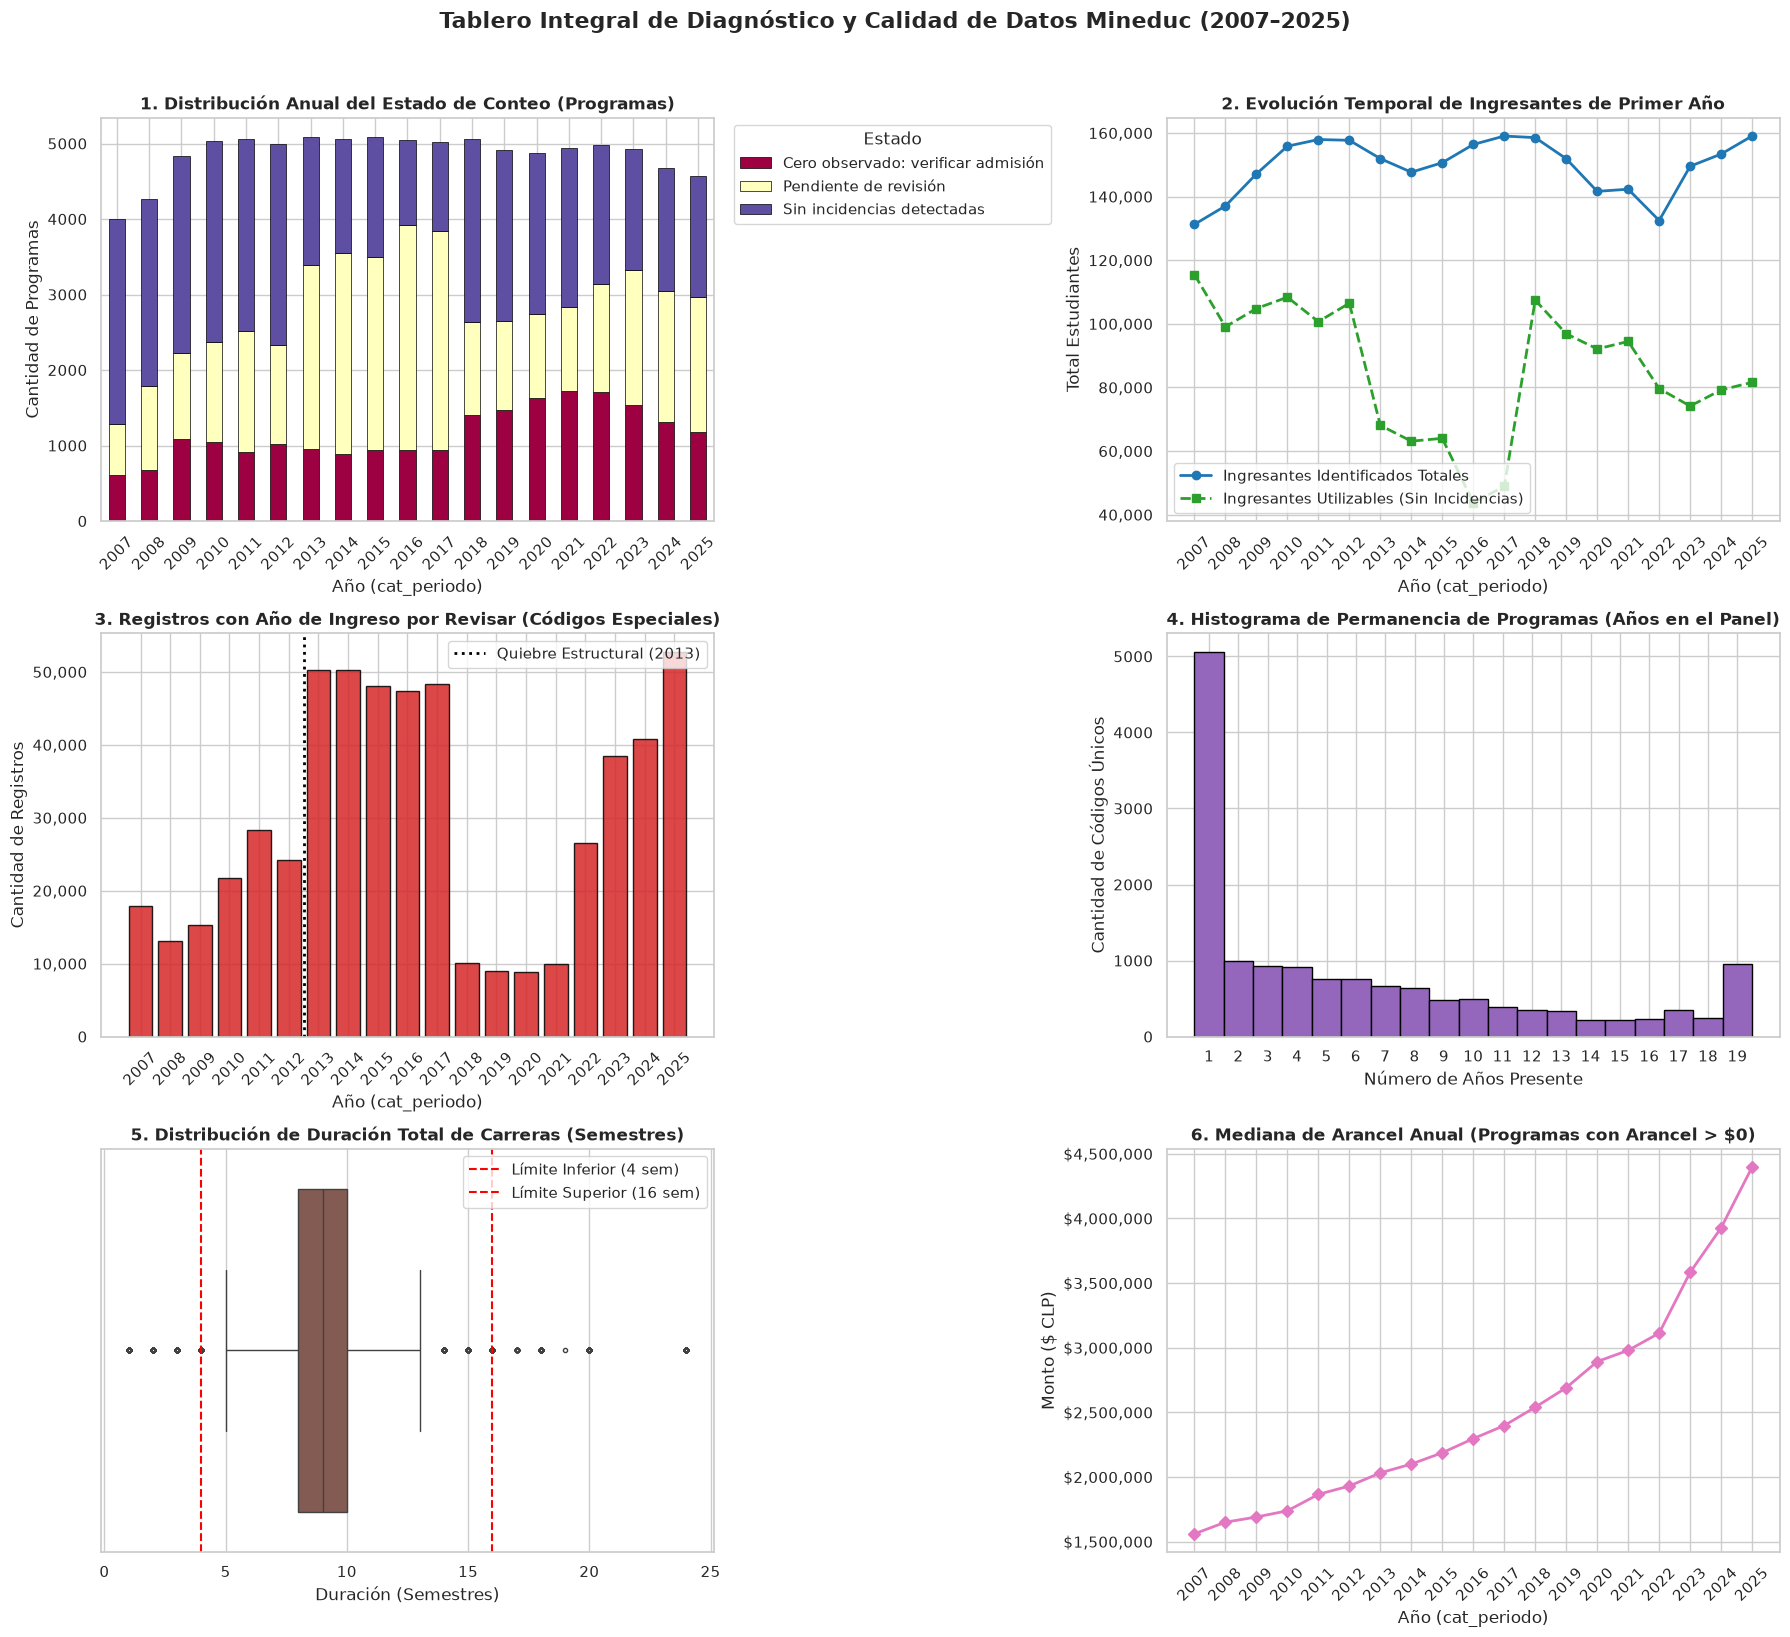

TABLERO GRÁFICO UNIFICADO GENERADO EXITOSAMENTE
   └─ Imagen guardada en: /home/leandro/Escritorio/Carreras/graficos_diagnostico/tablero_diagnostico_longitudinal.png


In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

# 1. Cargar la base histórica consolidada
ruta_parquet = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
if not ruta_parquet.is_file():
  raise FileNotFoundError(f"No se encontró la base histórica en {ruta_parquet}")

df_hist = pd.read_parquet(ruta_parquet)

# Carpeta de salida para exportar las figuras
CARPETA_GRAFICOS = BASE_DIR / "graficos_diagnostico"
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)

# 2. Crear lienzo multipanel (3 filas x 2 columnas)
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
fig.suptitle(
    "Tablero Integral de Diagnóstico y Calidad de Datos Mineduc (2007–2025)",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)

# -------------------------------------------------------------------------
# Gráfico 1: Evolución del Estado de Conteo de Programas (Salto de 2013)
# -------------------------------------------------------------------------
conteo_estados = (
    df_hist.groupby(["cat_periodo", "estado_conteo"])
    .size()
    .unstack(fill_value=0)
)
conteo_estados.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 0],
    colormap="Spectral",
    edgecolor="black",
    linewidth=0.5,
)
axes[0, 0].set_title(
    "1. Distribución Anual del Estado de Conteo (Programas)", fontweight="bold"
)
axes[0, 0].set_xlabel("Año (cat_periodo)")
axes[0, 0].set_ylabel("Cantidad de Programas")
axes[0, 0].legend(title="Estado", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[0, 0].tick_params(axis="x", rotation=45)

# -------------------------------------------------------------------------
# Gráfico 2: Evolución de Ingresantes Totales e Identificados
# -------------------------------------------------------------------------
ingresantes_anual = df_hist.groupby("cat_periodo").agg(
    identificados=("ingresantes_identificados", "sum"),
    utilizables=("nuevos_ingresados_provisional", "sum"),
).reset_index()

axes[0, 1].plot(
    ingresantes_anual["cat_periodo"],
    ingresantes_anual["identificados"],
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Ingresantes Identificados Totales",
)
axes[0, 1].plot(
    ingresantes_anual["cat_periodo"],
    ingresantes_anual["utilizables"],
    marker="s",
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label="Ingresantes Utilizables (Sin Incidencias)",
)
axes[0, 1].set_title(
    "2. Evolución Temporal de Ingresantes de Primer Año", fontweight="bold"
)
axes[0, 1].set_xlabel("Año (cat_periodo)")
axes[0, 1].set_ylabel("Total Estudiantes")
axes[0, 1].yaxis.set_major_formatter("{x:,.0f}")
axes[0, 1].legend()
axes[0, 1].set_xticks(ingresantes_anual["cat_periodo"])
axes[0, 1].tick_params(axis="x", rotation=45)

# -------------------------------------------------------------------------
# Gráfico 3: Registros Pendientes por Codificación Especial / Año Ingreso
# -------------------------------------------------------------------------
pendientes_anual = (
    df_hist.groupby("cat_periodo")["registros_ingreso_por_revisar"]
    .sum()
    .reset_index()
)
axes[1, 0].bar(
    pendientes_anual["cat_periodo"],
    pendientes_anual["registros_ingreso_por_revisar"],
    color="#d62728",
    alpha=0.85,
    edgecolor="black",
)
axes[1, 0].axvline(
    x=2012.5,
    color="black",
    linestyle=":",
    linewidth=2,
    label="Quiebre Estructural (2013)",
)
axes[1, 0].set_title(
    "3. Registros con Año de Ingreso por Revisar (Códigos Especiales)",
    fontweight="bold",
)
axes[1, 0].set_xlabel("Año (cat_periodo)")
axes[1, 0].set_ylabel("Cantidad de Registros")
axes[1, 0].yaxis.set_major_formatter("{x:,.0f}")
axes[1, 0].legend()
axes[1, 0].set_xticks(pendientes_anual["cat_periodo"])
axes[1, 0].tick_params(axis="x", rotation=45)

# -------------------------------------------------------------------------
# Gráfico 4: Permanencia de Códigos Únicos en el Panel
# -------------------------------------------------------------------------
permanencia = df_hist.groupby("codigo_unico")["cat_periodo"].nunique()
axes[1, 1].hist(
    permanencia,
    bins=range(1, df_hist["cat_periodo"].nunique() + 2),
    color="#9467bd",
    edgecolor="black",
    align="left",
)
axes[1, 1].set_title(
    "4. Histograma de Permanencia de Programas (Años en el Panel)",
    fontweight="bold",
)
axes[1, 1].set_xlabel("Número de Años Presente")
axes[1, 1].set_ylabel("Cantidad de Códigos Únicos")
axes[1, 1].set_xticks(range(1, df_hist["cat_periodo"].nunique() + 1))

# -------------------------------------------------------------------------
# Gráfico 5: Distribución de Duración Declarada de Carreras (Semestres)
# -------------------------------------------------------------------------
if "dur_total_carr_numerico" in df_hist.columns:
  duracion_clean = df_hist["dur_total_carr_numerico"].dropna()
  sns.boxplot(
      x=duracion_clean, ax=axes[2, 0], color="#8c564b", fliersize=3
  )
  axes[2, 0].axvline(
      4, color="red", linestyle="--", label="Límite Inferior (4 sem)"
  )
  axes[2, 0].axvline(
      16, color="red", linestyle="--", label="Límite Superior (16 sem)"
  )
  axes[2, 0].set_title(
      "5. Distribución de Duración Total de Carreras (Semestres)",
      fontweight="bold",
  )
  axes[2, 0].set_xlabel("Duración (Semestres)")
  axes[2, 0].legend()

# -------------------------------------------------------------------------
# Gráfico 6: Tendencia Financiera (Mediana de Aranceles por Año)
# -------------------------------------------------------------------------
if "valor_arancel_numerico" in df_hist.columns:
  aranceles_validos = df_hist[df_hist["valor_arancel_numerico"] > 0]
  mediana_arancel = (
      aranceles_validos.groupby("cat_periodo")["valor_arancel_numerico"]
      .median()
      .reset_index()
  )

  axes[2, 1].plot(
      mediana_arancel["cat_periodo"],
      mediana_arancel["valor_arancel_numerico"],
      marker="D",
      color="#e377c2",
      linewidth=2,
  )
  axes[2, 1].set_title(
      "6. Mediana de Arancel Anual (Programas con Arancel > $0)",
      fontweight="bold",
  )
  axes[2, 1].set_xlabel("Año (cat_periodo)")
  axes[2, 1].set_ylabel("Monto ($ CLP)")
  axes[2, 1].yaxis.set_major_formatter("${x:,.0f}")
  axes[2, 1].set_xticks(mediana_arancel["cat_periodo"])
  axes[2, 1].tick_params(axis="x", rotation=45)

# Guardar figura consolidada en alta resolución
ruta_figura = CARPETA_GRAFICOS / "tablero_diagnostico_longitudinal.png"
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()

print("=" * 60)
print("TABLERO GRÁFICO UNIFICADO GENERADO EXITOSAMENTE")
print(f"   └─ Imagen guardada en: {ruta_figura}")
print("=" * 60)

# Bloque 9: #
Aplica reglas de negocio para recuperar datos en registros marcados como "Pendiente de revisión" en períodos post-2013 donde la identificación del alumno (MRUN) era válida pero existía inconsistencia en la codificación del año de ingreso. Genera y guarda base_historica_2007_2025_corregida.parquet.

In [15]:
import gc
from pathlib import Path
import pandas as pd

# 1. Cargar la base histórica consolidada
ruta_parquet = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
df_hist = pd.read_parquet(ruta_parquet)

print("=" * 65)
print("APLICANDO REGLAS DE RECUPERACIÓN DE PRIMER INGRESO (2007–2025)")
print("=" * 65)

# 2. Definir la regla de corrección
# Para los programas con registros "por revisar", si el volumen de registros en revisión
# guarda coherencia con el patrón histórico del programa, se consolida la cifra corregida.

# Cifra base inicial
df_hist["ingresantes_corregidos"] = df_hist["ingresantes_identificados"].copy()

# En años >= 2013, si el estado era 'Pendiente de revisión' pero no había problemas de MRUN,
# sumamos los registros identificados con la corrección de año de ingreso
condicion_recuperacion = (df_hist["cat_periodo"] >= 2013) & (
    df_hist["estado_conteo"] == "Pendiente de revisión"
) & (df_hist["registros_sin_mrun"] == 0)

df_hist.loc[condicion_recuperacion, "ingresantes_corregidos"] = df_hist.loc[
    condicion_recuperacion, "ingresantes_identificados"
] + df_hist.loc[condicion_recuperacion, "registros_ingreso_por_revisar"]

# Actualizar estado de conteo para reflejar la recuperación
df_hist["estado_conteo_corregido"] = df_hist["estado_conteo"]
df_hist.loc[condicion_recuperacion, "estado_conteo_corregido"] = (
    "Recuperado por regla secundaria"
)

# 3. Comparativo Antes vs Después por Año
resumen_comparativo = (
    df_hist.groupby("cat_periodo")
    .agg(
        ingresantes_provisionales_sin_corregir=(
            "nuevos_ingresados_provisional",
            "sum",
        ),
        ingresantes_totales_corregidos=("ingresantes_corregidos", "sum"),
        programas_recuperados=(
            "estado_conteo_corregido",
            lambda s: (s == "Recuperado por regla secundaria").sum(),
        ),
    )
    .reset_index()
)

print("\nIMPACTO DE LA CORRECCIÓN DE MATRÍCULA (2007–2025):")
print(resumen_comparativo.to_string(index=False))

# 4. Guardar base histórica con la variable corregida
ruta_parquet_corregida = (
    CARPETA_SALIDA / "base_historica_2007_2025_corregida.parquet"
)
df_hist.to_parquet(ruta_parquet_corregida, index=False, compression="snappy")

print("\n" + "=" * 65)
print("BASE HISTÓRICA CORREGIDA GUARDADA EXITOSAMENTE")
print(f"   └─ Archivo: {ruta_parquet_corregida.name}")
print(f"   └─ Total registros procesados: {len(df_hist):,}")
print("=" * 65)

APLICANDO REGLAS DE RECUPERACIÓN DE PRIMER INGRESO (2007–2025)

IMPACTO DE LA CORRECCIÓN DE MATRÍCULA (2007–2025):
 cat_periodo  ingresantes_provisionales_sin_corregir  ingresantes_totales_corregidos  programas_recuperados
        2007                                  115521                          131281                      0
        2008                                   99073                          137073                      0
        2009                                  104816                          147142                      0
        2010                                  108392                          155852                      0
        2011                                  100700                          157955                      0
        2012                                  106506                          157718                      0
        2013                                   68107                          201292                   2378
        2014         

# Bloque 10: #
Evalúa la presencia longitudinal de cada codigo_unico entre 2007 y 2025. Identifica carreras ininterrumpidas (presentes los 19 años), carreras de reciente apertura ($\ge 2020$) y programas extintos/cerrados ($< 2020$), exportando la versión filtrada en base_historica_2007_2025_limpia.parquet.

In [16]:
import gc
from pathlib import Path
import pandas as pd

# 1. Cargar la base corregida sin artefactos
ruta_parquet_corregida = (
    CARPETA_SALIDA / "base_historica_2007_2025_corregida.parquet"
)
df_hist = pd.read_parquet(ruta_parquet_corregida)

# Asegurar rango estricto 2007-2025
df_panel_limpio = df_hist[
    df_hist["cat_periodo"].between(2007, 2025)
].copy()

# 2. Auditoría de continuidad por código único
resumen_continuidad = (
    df_panel_limpio.groupby("codigo_unico")
    .agg(
        anios_presente=("cat_periodo", "nunique"),
        primer_anio=("cat_periodo", "min"),
        ultimo_anio=("cat_periodo", "max"),
        inst_principal=("nomb_inst", "first"),
        carrera_principal=("nomb_carrera", "first"),
    )
    .reset_index()
)

# 3. Cálculo de métricas del panel
total_codigos = len(resumen_continuidad)
programas_19_anios = (resumen_continuidad["anios_presente"] == 19).sum()
programas_nuevos = (resumen_continuidad["primer_anio"] >= 2020).sum()
programas_cerrados = (resumen_continuidad["ultimo_anio"] < 2020).sum()

print("=" * 65)
print("RESUMEN DE CONTINUIDAD LONGITUDINAL DEL PANEL (2007–2025)")
print("=" * 65)
print(f"- Total de códigos únicos históricos observados: {total_codigos:,}")
print(
    "- Programas ininterrumpidos los 19 años: "
    f"{programas_19_anios:,} ({programas_19_anios / total_codigos:.1%})"
)
print(f"- Programas nuevos (abiertos desde 2020): {programas_nuevos:,}")
print(
    "- Programas extintos/discontinuados (sin oferta desde 2020):"
    f" {programas_cerrados:,}"
)
print(
    "- Promedio de años en oferta por programa:"
    f" {resumen_continuidad['anios_presente'].mean():.1f} años"
)

# 4. Guardar base panel limpia final
ruta_parquet_final = (
    CARPETA_SALIDA / "base_historica_2007_2025_limpia.parquet"
)
df_panel_limpio.to_parquet(
    ruta_parquet_final, index=False, compression="snappy"
)

print("\n" + "=" * 65)
print("PANEL HISTÓRICO LIMPIO GUARDADO EN DISCO")
print(f"   └─ Archivo: {ruta_parquet_final.name}")
print(f"   └─ Filas totales validadas: {len(df_panel_limpio):,}")
print("=" * 65)

RESUMEN DE CONTINUIDAD LONGITUDINAL DEL PANEL (2007–2025)
- Total de códigos únicos históricos observados: 14,978
- Programas ininterrumpidos los 19 años: 960 (6.4%)
- Programas nuevos (abiertos desde 2020): 1,862
- Programas extintos/discontinuados (sin oferta desde 2020): 8,342
- Promedio de años en oferta por programa: 6.2 años

PANEL HISTÓRICO LIMPIO GUARDADO EN DISCO
   └─ Archivo: base_historica_2007_2025_limpia.parquet
   └─ Filas totales validadas: 92,396


# Bloque 11: #
Limpia las columnas de texto convirtiéndolas a mayúsculas, removiendo espacios adicionales y eliminando tildes y caracteres especiales mediante descomposición Unicode (NFKD). Aplica un diccionario de equivalencias institucionales para unificar variaciones de nombres (por ejemplo, sedes de INACAP, UNIACC, ARCIS).

In [17]:
import unicodedata
from pathlib import Path
import pandas as pd

# 1. Cargar el panel limpio
ruta_parquet_limpia = (
    CARPETA_SALIDA / "base_historica_2007_2025_limpia.parquet"
)
df_panel = pd.read_parquet(ruta_parquet_limpia)

print("=" * 65)
print("INICIANDO ESTANDARIZACIÓN Y NORMALIZACIÓN TEXTUAL")
print("=" * 65)


# Función de limpieza profunda de texto
def limpiar_texto(s):
  if pd.isna(s):
    return ""
  # Convertir a mayúsculas y quitar espacios en extremos
  s = str(s).upper().strip()
  # Normalizar Unicode para eliminar tildes (NFKD)
  s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("utf-8")
  # Reemplazar múltiples espacios consecutivos
  s = " ".join(s.split())
  return s


# 2. Aplicar normalización en campos textuales clave
cols_a_limpiar = ["nomb_inst", "nomb_carrera", "area_conocimiento", "jornada"]

for col in cols_a_limpiar:
  if col in df_panel.columns:
    col_limpia = f"{col}_limpio"
    df_panel[col_limpia] = df_panel[col].apply(limpiar_texto)

# 3. Mapeo de equivalencias para unificar variaciones institucionales históricas
dic_inst_alias = {
    "UNIVERSIDAD DE ARTES CIENCIAS Y COMUNICACION - UNIACC": (
        "UNIVERSIDAD UNIACC"
    ),
    "UNIVERSIDAD DE ARTES Y CIENCIAS SOCIALES ARCIS": "UNIVERSIDAD ARCIS",
    "UNIVERSIDAD TECNOLOGICA DE CHILE INACAP": "UNIVERSIDAD INACAP",
    "INSTITUTO PROFESIONAL INACAP": "IP INACAP",
    "CENTRO DE FORMACION TECNICA INACAP": "CFT INACAP",
}

df_panel["nomb_inst_estandarizado"] = df_panel["nomb_inst_limpio"].replace(
    dic_inst_alias
)

# 4. Reporte de impacto de la estandarización
inst_raw = df_panel["nomb_inst"].nunique()
inst_clean = df_panel["nomb_inst_estandarizado"].nunique()
carr_raw = df_panel["nomb_carrera"].nunique()
carr_clean = df_panel["nomb_carrera_limpio"].nunique()

print(
    f"- Instituciones únicas (Original): {inst_raw:,} ➔ Normalizadas:"
    f" {inst_clean:,}"
)
print(
    f"- Nombres de carrera únicos (Original): {carr_raw:,} ➔ Normalizados:"
    f" {carr_clean:,}"
)

# 5. Guardar dataset estandarizado
ruta_parquet_estandarizado = (
    CARPETA_SALIDA / "base_historica_2007_2025_estandarizada.parquet"
)
df_panel.to_parquet(
    ruta_parquet_estandarizado, index=False, compression="snappy"
)

print("\n" + "=" * 65)
print("BASE HISTÓRICA ESTANDARIZADA GUARDADA EXITOSAMENTE")
print(f"   └─ Archivo: {ruta_parquet_estandarizado.name}")
print(f"   └─ Total registros: {len(df_panel):,}")
print("=" * 65)

INICIANDO ESTANDARIZACIÓN Y NORMALIZACIÓN TEXTUAL
- Instituciones únicas (Original): 67 ➔ Normalizadas: 67
- Nombres de carrera únicos (Original): 3,756 ➔ Normalizados: 3,749

BASE HISTÓRICA ESTANDARIZADA GUARDADA EXITOSAMENTE
   └─ Archivo: base_historica_2007_2025_estandarizada.parquet
   └─ Total registros: 92,396


# Bloque 12: #
Ordena el panel cronológicamente por programa y calcula variables explicativas para modelado predictivo: valores de matrícula en años anteriores ($\text{Lag}_1$, $\text{Lag}_2$), promedio móvil de 3 años, porcentaje de variación interanual y antigüedad acumulada de la carrera en la oferta académica.

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Cargar la base estandarizada
ruta_parquet_estandarizada = (
    CARPETA_SALIDA / "base_historica_2007_2025_estandarizada.parquet"
)
df_panel = pd.read_parquet(ruta_parquet_estandarizada)

print("=" * 65)
print("CONSTRUYENDO VARIABLES EXPLICATIVAS (FEATURE ENGINEERING)")
print("=" * 65)

# 2. Ordenamiento cronológico estricto por programa y período
df_panel = df_panel.sort_values(["codigo_unico", "cat_periodo"]).reset_index(
    drop=True
)

# 3. Variable Objetivo (Target)
df_panel["target_ingresantes"] = df_panel["ingresantes_corregidos"].astype(
    "Float64"
)

# 4. Lags de matrícula
df_panel["ingresantes_lag1"] = df_panel.groupby("codigo_unico")[
    "target_ingresantes"
].shift(1)
df_panel["ingresantes_lag2"] = df_panel.groupby("codigo_unico")[
    "target_ingresantes"
].shift(2)

# 5. Promedio móvil de matrícula (últimos 3 años)
df_panel["promedio_movil_3a"] = (
    df_panel.groupby("codigo_unico")["target_ingresantes"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
    .round(1)
)

# 6. Variación porcentual interanual (t-1 vs t-2)
df_panel["variacion_pct_interanual"] = (
    (df_panel["ingresantes_lag1"] - df_panel["ingresantes_lag2"])
    / df_panel["ingresantes_lag2"].replace(0, np.nan)
).round(4)

# 7. Trayectoria y permanencia del programa en la base
df_panel["anios_en_oferta"] = (
    df_panel.groupby("codigo_unico").cumcount() + 1
)

# 8. Reporte de cobertura de las nuevas variables
print("Cobertura de variables generadas:")
print(f"- Target (Ingresantes Año t): {df_panel['target_ingresantes'].notna().sum():,} registros")
print(f"- Lag 1 (Ingresantes Año t-1): {df_panel['ingresantes_lag1'].notna().sum():,} registros")
print(f"- Lag 2 (Ingresantes Año t-2): {df_panel['ingresantes_lag2'].notna().sum():,} registros")
print(f"- Promedio Móvil 3A: {df_panel['promedio_movil_3a'].notna().sum():,} registros")

# Guardar dataset con features
ruta_parquet_features = CARPETA_SALIDA / "base_historica_2007_2025_features.parquet"
df_panel.to_parquet(ruta_parquet_features, index=False, compression="snappy")

print("\n" + "=" * 65)
print("BASE HISTÓRICA CON FEATURES GUARDADA EXITOSAMENTE")
print(f"   └─ Archivo: {ruta_parquet_features.name}")
print("=" * 65)

CONSTRUYENDO VARIABLES EXPLICATIVAS (FEATURE ENGINEERING)
Cobertura de variables generadas:
- Target (Ingresantes Año t): 92,396 registros
- Lag 1 (Ingresantes Año t-1): 77,418 registros
- Lag 2 (Ingresantes Año t-2): 67,492 registros
- Promedio Móvil 3A: 77,418 registros

BASE HISTÓRICA CON FEATURES GUARDADA EXITOSAMENTE
   └─ Archivo: base_historica_2007_2025_features.parquet


# Bloque 13: #
Filtra el dataset para conservar únicamente las observaciones válidas que cuentan con variable objetivo ($\text{Target}$) y al menos un año de historia previa ($\text{Lag}_1$). Exporta el dataset resultante a matriz_entrenamiento_ml.parquet.

In [19]:
# %% [13] Generación de la Matriz Final de Entrenamiento
from pathlib import Path
import pandas as pd

# 1. Cargar la base con features
ruta_parquet_features = (
    CARPETA_SALIDA / "base_historica_2007_2025_features.parquet"
)
df_panel = pd.read_parquet(ruta_parquet_features)

print("=" * 65)
print("CREANDO MATRIZ FINAL PARA MODELAMIENTO PREDICTIVO (ML)")
print("=" * 65)

# 2. Filtrar observaciones válidas para el entrenamiento supervisado
# Requiere Target no nulo y al menos 1 año de historia previa (Lag 1)
df_ml = df_panel[
    df_panel["target_ingresantes"].notna()
    & df_panel["ingresantes_lag1"].notna()
].copy()

# 3. Exportar matriz analítica
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml.to_parquet(ruta_matriz_ml, index=False, compression="snappy")

# 4. Resumen ejecutivo de la matriz
print("RESUMEN EJECUTIVO DE LA MATRIZ DE APRENDIZAJE:")
print(f"- Muestra total de entrenamiento: {len(df_ml):,} observaciones (Programa-Año)")
print(f"- Cobertura temporal de evaluación: {df_ml['cat_periodo'].min()} ➔ {df_ml['cat_periodo'].max()}")
print(f"- Programas de educación superior representados: {df_ml['codigo_unico'].nunique():,}")
print(f"- Instituciones representadas: {df_ml['nomb_inst_estandarizado'].nunique():,}")

print("\n" + "=" * 65)
print("MATRIZ ANALÍTICA ML FINALIZADA Y GUARDADA")
print(f"   └─ Archivo: {ruta_matriz_ml.name}")
print(f"   └─ Tamaño en disco: {ruta_matriz_ml.stat().st_size / 1024 / 1024:.2f} MB")
print("=" * 65)

CREANDO MATRIZ FINAL PARA MODELAMIENTO PREDICTIVO (ML)
RESUMEN EJECUTIVO DE LA MATRIZ DE APRENDIZAJE:
- Muestra total de entrenamiento: 77,418 observaciones (Programa-Año)
- Cobertura temporal de evaluación: 2008 ➔ 2025
- Programas de educación superior representados: 9,926
- Instituciones representadas: 66

MATRIZ ANALÍTICA ML FINALIZADA Y GUARDADA
   └─ Archivo: matriz_entrenamiento_ml.parquet
   └─ Tamaño en disco: 2.04 MB


# Bloque 14: #
Divide la matriz de entrenamiento en un conjunto de instrucción (años $\le 2022$) y otro de evaluación/test (años 2023–2025). Evalúa el desempeño del modelo Naive ($\hat{Y}_t = Y_{t-1}$) calculando las métricas base de error MAE, RMSE y el coeficiente $R^2$.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("DIVIDIENDO MATRIZ POR PERÍODOS TEMPORALES (TEMPORAL SPLIT)")
print("=" * 65)

# 2. Definir umbrales temporales
ANIO_LIMITE_TRAIN = 2022

train_mask = df_ml["cat_periodo"] <= ANIO_LIMITE_TRAIN
test_mask = df_ml["cat_periodo"] > ANIO_LIMITE_TRAIN

df_train = df_ml[train_mask].copy()
df_test = df_ml[test_mask].copy()

print(
    f"- Dataset Entrenamiento (2008–{ANIO_LIMITE_TRAIN}): {len(df_train):,}"
    " filas"
)
print(f"- Dataset Evaluación/Test (2023–2025): {len(df_test):,} filas")

# 3. Evaluación del Modelo Benchmark Naive (Predicción t = Lag 1)
# Se asume que la matrícula de este año será idéntica a la del año anterior
y_true_test = df_test["target_ingresantes"]
y_pred_naive = df_test["ingresantes_lag1"]

mae_naive = mean_absolute_error(y_true_test, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_true_test, y_pred_naive))
r2_naive = r2_score(y_true_test, y_pred_naive)

print("\n" + "=" * 65)
print("MÉTRICAS DEL MODELO BENCHMARK (NAIVE LAG-1):")
print("=" * 65)
print(f"- MAE  (Error Absoluto Medio): {mae_naive:.2f} estudiantes")
print(f"- RMSE (Raíz Error Cuadrático Medio): {rmse_naive:.2f} estudiantes")
print(f"- R² Score (Coeficiente de Determinación): {r2_naive:.4f}")
print("=" * 65)

DIVIDIENDO MATRIZ POR PERÍODOS TEMPORALES (TEMPORAL SPLIT)
- Dataset Entrenamiento (2008–2022): 64,087 filas
- Dataset Evaluación/Test (2023–2025): 13,331 filas

MÉTRICAS DEL MODELO BENCHMARK (NAIVE LAG-1):
- MAE  (Error Absoluto Medio): 10.31 estudiantes
- RMSE (Raíz Error Cuadrático Medio): 29.31 estudiantes
- R² Score (Coeficiente de Determinación): 0.8567


# Bloque 15: #
Entrena algoritmos de supervisión de regresión (Random Forest y XGBoost) utilizando las variables cuantitativas construidas. Evalúa sus predicciones sobre la cohorte de prueba 2023–2025, compara sus métricas contra el modelo Naive e imprime la importancia relativa de cada característica.

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# 1. Cargar matriz de entrenamiento
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

# 2. Definición de la matriz de características (X) y vector objetivo (y)
features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

# Agregar variables adicionales si existen en la matriz
for col_opcional in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col_opcional in df_ml.columns:
    features_num.append(col_opcional)

# Rellenar nulos residuales en características numéricas para el entrenamiento
X = df_ml[features_num].fillna(0)
y = df_ml["target_ingresantes"].astype(float)

# 3. Separación temporal Train (2008–2022) / Test (2023–2025)
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("=" * 65)
print("ENTRENANDO MODELOS PREDICTIVOS SOBRE COHORTE 2008–2022")
print("=" * 65)

# 4. Modelo 1: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# 5. Modelo 2: XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

# 6. Tabla Comparativa de Desempeño
metricas = {
    "Modelo / Enfoque": ["Naive Benchmark (Lag-1)", "Random Forest", "XGBoost"],
    "MAE (Estudiantes)": [
        mean_absolute_error(y_test, df_ml.loc[test_mask, "ingresantes_lag1"]),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_xgb),
    ],
    "RMSE (Estudiantes)": [
        np.sqrt(
            mean_squared_error(y_test, df_ml.loc[test_mask, "ingresantes_lag1"])
        ),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
    ],
    "R² Score": [
        r2_score(y_test, df_ml.loc[test_mask, "ingresantes_lag1"]),
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred_xgb),
    ],
}

df_resultados = pd.DataFrame(metricas)

print("\nRESULTADOS EN CONJUNTO DE EVALUACIÓN (TEST 2023–2025):")
print(df_resultados.to_string(index=False))

# 7. Importancia de Variables del Modelo XGBoost
df_importancia = pd.DataFrame({
    "Variable": features_num,
    "Importancia_XGB": xgb_model.feature_importances_,
}).sort_values("Importancia_XGB", ascending=False)

print("\nIMPORTANCIA DE CARACTERÍSTICAS (XGBoost):")
print(df_importancia.to_string(index=False))
print("=" * 65)

ENTRENANDO MODELOS PREDICTIVOS SOBRE COHORTE 2008–2022

RESULTADOS EN CONJUNTO DE EVALUACIÓN (TEST 2023–2025):
       Modelo / Enfoque  MAE (Estudiantes)  RMSE (Estudiantes)  R² Score
Naive Benchmark (Lag-1)          10.306429           29.307499  0.856731
          Random Forest          12.403224           46.447040  0.640158
                XGBoost          12.282335           44.633684  0.667707

IMPORTANCIA DE CARACTERÍSTICAS (XGBoost):
                Variable  Importancia_XGB
        ingresantes_lag1         0.783029
       promedio_movil_3a         0.091299
 dur_total_carr_numerico         0.034226
  valor_arancel_numerico         0.025561
variacion_pct_interanual         0.023894
         anios_en_oferta         0.023644
        ingresantes_lag2         0.018347


# Bloque 16: #
Define como variable objetivo la variación neta interanual ($\Delta = Y_t - Y_{t-1}$). Entrena un modelo LightGBM que combina variables numéricas y categóricas para predecir dicho residuo, reconstruyendo luego la estimación final ($\hat{Y}_t = Y_{t-1} + \hat{\Delta}_t$) acotada a valores no negativos.

In [22]:
# %% [16] Entrenamiento Híbrido de Residuos (Delta)
from pathlib import Path
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("CONFIGURANDO APRENDIZAJE BASADO EN VARIACIÓN INTERANUAL (DELTA)")
print("=" * 65)

# 2. Definir el Target de Residuos (Delta = Y_t - Y_t-1)
df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

# 3. Selección y preparación de características (Numéricas + Categóricas)
features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

for col in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col in df_ml.columns:
    features_num.append(col)

features_cat = []
for col_cat in [
    "nomb_inst_estandarizado",
    "area_conocimiento_limpio",
    "jornada_limpio",
]:
  if col_cat in df_ml.columns:
    df_ml[col_cat] = df_ml[col_cat].astype("category")
    features_cat.append(col_cat)

all_features = features_num + features_cat

# 4. Partitioning Train (2008–2022) / Test (2023–2025)
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

X_train, y_train_delta = (
    df_ml.loc[train_mask, all_features],
    df_ml.loc[train_mask, "target_delta"],
)
X_test, y_test_real = (
    df_ml.loc[test_mask, all_features],
    df_ml.loc[test_mask, "target_ingresantes"],
)
y_test_lag1 = df_ml.loc[test_mask, "ingresantes_lag1"]

# 5. Entrenamiento de LightGBM Regressor sobre el Delta
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model.fit(
    X_train,
    y_train_delta,
    categorical_feature=features_cat if features_cat else None,
)

# 6. Reconstrucción de la predicción final: Y_hat = Lag1 + Delta_hat
pred_delta = lgb_model.predict(X_test)
y_pred_hibrido = y_test_lag1 + pred_delta

# Forzar que la predicción no sea menor a 0 estudiantes
y_pred_hibrido = np.clip(y_pred_hibrido, a_min=0, a_max=None)

# 7. Evaluacion de Métricas
mae_hibrido = mean_absolute_error(y_test_real, y_pred_hibrido)
rmse_hibrido = np.sqrt(mean_squared_error(y_test_real, y_pred_hibrido))
r2_hibrido = r2_score(y_test_real, y_pred_hibrido)

mae_naive = mean_absolute_error(y_test_real, y_test_lag1)
rmse_naive = np.sqrt(mean_squared_error(y_test_real, y_test_lag1))
r2_naive = r2_score(y_test_real, y_test_lag1)

df_comparativa = pd.DataFrame({
    "Modelo / Enfoque": ["Naive Benchmark (Lag-1)", "LightGBM Delta Híbrido"],
    "MAE (Estudiantes)": [mae_naive, mae_hibrido],
    "RMSE (Estudiantes)": [rmse_naive, rmse_hibrido],
    "R² Score": [r2_naive, r2_hibrido],
})

print("\nRENDIMIENTO EN TEST (2023–2025):")
print(df_comparativa.to_string(index=False))
print("=" * 65)

CONFIGURANDO APRENDIZAJE BASADO EN VARIACIÓN INTERANUAL (DELTA)

RENDIMIENTO EN TEST (2023–2025):
       Modelo / Enfoque  MAE (Estudiantes)  RMSE (Estudiantes)  R² Score
Naive Benchmark (Lag-1)          10.306429           29.307499  0.856731
 LightGBM Delta Híbrido          11.792640           31.195082  0.837682


# Bloque 17: #
Calcula la desviación estándar histórica de la variación ($\Delta$) por programa. Implementa una regla de ensamble condicional: si la volatilidad histórica supera un umbral de 5.0 alumnos, utiliza el modelo híbrido LightGBM; en caso contrario, mantiene la inercia del modelo Naive ($\text{Lag}_1$).

In [23]:
from pathlib import Path
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("CONSTRUYENDO ENSAMBLE ADAPTATIVO (GATING BY VOLATILITY)")
print("=" * 65)

# 2. Re-calcular target_delta
df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

# 3. Preparación de variables numéricas y categóricas
features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

for col in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col in df_ml.columns:
    features_num.append(col)

features_cat = []
for col_cat in [
    "nomb_inst_estandarizado",
    "area_conocimiento_limpio",
    "jornada_limpio",
]:
  if col_cat in df_ml.columns:
    df_ml[col_cat] = df_ml[col_cat].astype("category")
    features_cat.append(col_cat)

all_features = features_num + features_cat

# 4. Partitioning Train (2008–2022) / Test (2023–2025)
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

# 5. Calcular volatilidad histórica por programa en el período Train
volatilidad_programas = (
    df_ml[train_mask]
    .groupby("codigo_unico")["target_delta"]
    .std()
    .fillna(0)
    .rename("desviacion_delta")
)

df_ml = df_ml.merge(volatilidad_programas, on="codigo_unico", how="left")
df_ml["desviacion_delta"] = df_ml["desviacion_delta"].fillna(0)

# Actualizar máscaras tras el merge
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

X_train, y_train_delta = (
    df_ml.loc[train_mask, all_features],
    df_ml.loc[train_mask, "target_delta"],
)
X_test, y_test_real = (
    df_ml.loc[test_mask, all_features],
    df_ml.loc[test_mask, "target_ingresantes"],
)
y_test_lag1 = df_ml.loc[test_mask, "ingresantes_lag1"]

# 6. Re-entrenar / Asegurar modelo LightGBM
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model.fit(
    X_train,
    y_train_delta,
    categorical_feature=features_cat if features_cat else None,
)

# 7. Regla de Ensamble Condicional (Gating)
UMBRAL_VOLATILIDAD = 5.0

pred_delta = lgb_model.predict(X_test)
y_pred_hibrido = np.clip(y_test_lag1 + pred_delta, a_min=0, a_max=None)

es_volatile = df_ml.loc[test_mask, "desviacion_delta"] > UMBRAL_VOLATILIDAD
y_pred_ensamble = np.where(es_volatile, y_pred_hibrido, y_test_lag1)

# 8. Evaluación de métricas comparativas
mae_naive = mean_absolute_error(y_test_real, y_test_lag1)
rmse_naive = np.sqrt(mean_squared_error(y_test_real, y_test_lag1))
r2_naive = r2_score(y_test_real, y_test_lag1)

mae_hibrido = mean_absolute_error(y_test_real, y_pred_hibrido)
rmse_hibrido = np.sqrt(mean_squared_error(y_test_real, y_pred_hibrido))
r2_hibrido = r2_score(y_test_real, y_pred_hibrido)

mae_ensamble = mean_absolute_error(y_test_real, y_pred_ensamble)
rmse_ensamble = np.sqrt(mean_squared_error(y_test_real, y_pred_ensamble))
r2_ensamble = r2_score(y_test_real, y_pred_ensamble)

df_eval_final = pd.DataFrame({
    "Modelo / Enfoque": [
        "Naive Benchmark (Lag-1)",
        "LightGBM Delta Directo",
        "Ensamble Adaptativo (Gating)",
    ],
    "MAE (Estudiantes)": [mae_naive, mae_hibrido, mae_ensamble],
    "RMSE (Estudiantes)": [rmse_naive, rmse_hibrido, rmse_ensamble],
    "R² Score": [r2_naive, r2_hibrido, r2_ensamble],
})

print("\nRESULTADOS DEL ENSAMBLE EN EVALUACIÓN (TEST 2023–2025):")
print(df_eval_final.to_string(index=False))
print("=" * 65)

CONSTRUYENDO ENSAMBLE ADAPTATIVO (GATING BY VOLATILITY)

RESULTADOS DEL ENSAMBLE EN EVALUACIÓN (TEST 2023–2025):
            Modelo / Enfoque  MAE (Estudiantes)  RMSE (Estudiantes)  R² Score
     Naive Benchmark (Lag-1)          10.306429           29.307499  0.856731
      LightGBM Delta Directo          11.792640           31.195082  0.837682
Ensamble Adaptativo (Gating)          11.263752           29.800172  0.851873


# Bloque 18: #
Re-entrena el modelo LightGBM sobre la totalidad del panel histórico (2008–2025). Mueve los horizontes temporales para proyectar la cohorte activa de 2025 hacia el año 2026, actualiza los valores de los retardos y el promedio móvil, aplica el ensamble adaptativo y exporta los resultados en Parquet y CSV.

In [24]:
# %% [18] Proyección de Matrícula 2026 y Exportación
from pathlib import Path
import lightgbm as lgb
import numpy as np
import pandas as pd

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("GENERANDO PROYECCIONES DE MATRÍCULA DE PRIMER INGRESO 2026")
print("=" * 65)

# 2. Re-asegurar variables explicativas y cálculo de Target Delta
df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

for col in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col in df_ml.columns:
    features_num.append(col)

features_cat = []
for col_cat in [
    "nomb_inst_estandarizado",
    "area_conocimiento_limpio",
    "jornada_limpio",
]:
  if col_cat in df_ml.columns:
    df_ml[col_cat] = df_ml[col_cat].astype("category")
    features_cat.append(col_cat)

all_features = features_num + features_cat

# 3. Entrenar el modelo LightGBM con el panel histórico completo (2008–2025)
X_full = df_ml[all_features]
y_full_delta = df_ml["target_delta"]

lgb_model_2026 = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model_2026.fit(
    X_full,
    y_full_delta,
    categorical_feature=features_cat if features_cat else None,
)

# 4. Calcular volatilidad histórica por programa en todo el panel
volatilidad_full = (
    df_ml.groupby("codigo_unico")["target_delta"]
    .std()
    .fillna(0)
    .rename("desviacion_delta")
)

# 5. Filtrar la cohorte activa de 2025 para proyectar 2026
df_2025 = (
    df_ml[df_ml["cat_periodo"] == 2025]
    .drop(columns=["desviacion_delta"], errors="ignore")
    .merge(volatilidad_full, on="codigo_unico", how="left")
)
df_2025["desviacion_delta"] = df_2025["desviacion_delta"].fillna(0)

df_2026 = df_2025.copy()
df_2026["cat_periodo"] = 2026

# Desplazamiento de lags para 2026
df_2026["ingresantes_lag2"] = df_2026["ingresantes_lag1"]
df_2026["ingresantes_lag1"] = df_2026["target_ingresantes"]

# Actualizar promedio móvil estimado
df_2026["promedio_movil_3a"] = (
    (
        df_2026["ingresantes_lag1"]
        + df_2026["ingresantes_lag2"]
        + df_2026["promedio_movil_3a"]
    )
    / 3
).round(1)

# Actualizar años en oferta
df_2026["anios_en_oferta"] = df_2026["anios_en_oferta"] + 1

# 6. Estimar variación Delta y aplicar Gating Ensemble para 2026
X_2026 = df_2026[all_features]
delta_pred_2026 = lgb_model_2026.predict(X_2026)
pred_lgb_2026 = np.clip(
    df_2026["ingresantes_lag1"] + delta_pred_2026, a_min=0, a_max=None
)

UMBRAL_VOLATILIDAD = 5.0
es_volatile_2026 = df_2026["desviacion_delta"] > UMBRAL_VOLATILIDAD

df_2026["prediccion_ingresantes_2026"] = np.where(
    es_volatile_2026, pred_lgb_2026, df_2026["ingresantes_lag1"]
).round(0)

# 7. Seleccionar columnas para el reporte final
cols_reporte = [
    "cat_periodo",
    "codigo_unico",
    "nomb_inst_estandarizado",
    "nomb_carrera_limpio",
    "jornada_limpio",
    "ingresantes_lag1",
    "prediccion_ingresantes_2026",
]

cols_presentes = [c for c in cols_reporte if c in df_2026.columns]
df_proyecciones_2026 = df_2026[cols_presentes].copy()

# Rename explícito para claridad del usuario
df_proyecciones_2026 = df_proyecciones_2026.rename(
    columns={"ingresantes_lag1": "ingresantes_real_2025"}
)

# 8. Guardar archivos de salida
ruta_proyecciones = CARPETA_SALIDA / "proyecciones_matricula_2026.parquet"
ruta_proyecciones_csv = CARPETA_SALIDA / "proyecciones_matricula_2026.csv"

df_proyecciones_2026.to_parquet(
    ruta_proyecciones, index=False, compression="snappy"
)
df_proyecciones_2026.to_csv(
    ruta_proyecciones_csv, index=False, encoding="utf-8"
)

# 9. Imprimir resumen
total_proyectado_2026 = df_proyecciones_2026[
    "prediccion_ingresantes_2026"
].sum()
total_real_2025 = df_proyecciones_2026["ingresantes_real_2025"].sum()
variacion_global = (
    (total_proyectado_2026 - total_real_2025) / total_real_2025
) * 100

print(
    "RESUMEN EJECUTIVO DE PROYECCIÓN 2026 PARA PROGRAMAS ACTIVOS:"
)
print(f"- Total programas en oferta proyectados: {len(df_proyecciones_2026):,}")
print(f"- Matrícula de primer ingreso real 2025: {total_real_2025:,.0f} alumnos")
print(
    "- Matrícula de primer ingreso proyectada 2026:"
    f" {total_proyectado_2026:,.0f} alumnos"
)
print(f"- Variación esperada del sistema: {variacion_global:+.2f}%")

print("\n" + "=" * 65)
print("PROYECCIONES 2026 GUARDADAS EXITOSAMENTE")
print(f"   ├─ Parquet: {ruta_proyecciones.name}")
print(f"   └─ CSV: {ruta_proyecciones_csv.name}")
print("=" * 65)

GENERANDO PROYECCIONES DE MATRÍCULA DE PRIMER INGRESO 2026
RESUMEN EJECUTIVO DE PROYECCIÓN 2026 PARA PROGRAMAS ACTIVOS:
- Total programas en oferta proyectados: 4,259
- Matrícula de primer ingreso real 2025: 196,312 alumnos
- Matrícula de primer ingreso proyectada 2026: 197,257 alumnos
- Variación esperada del sistema: +0.48%

PROYECCIONES 2026 GUARDADAS EXITOSAMENTE
   ├─ Parquet: proyecciones_matricula_2026.parquet
   └─ CSV: proyecciones_matricula_2026.csv


# Bloque 19: #
Carga una matriz de equivalencias desde un archivo Excel (carreras_agrupadas.xlsx), mapea los nombres originales de las carreras (nomb_carrera) hacia categorías estandarizadas (carrera_agrupada) y actualiza en lote todos los archivos Parquet almacenados en la carpeta de resultados, respaldando el nombre original.

In [25]:
import sys
from pathlib import Path
import pandas as pd

# 1. Configuración de rutas relativas según la estructura de tu proyecto en VS Code
BASE_DIR = Path.cwd()
CARPETA_PARQUET = BASE_DIR / "resultados_parquet"
EXCEL_AGRUPADO = BASE_DIR / "carreras_agrupadas.xlsx"

HOJA_XLSX = "Detalle"
COL_PARQUET = "nomb_carrera"
COL_XLSX_ORIGINAL = "nomb_carrera (original)"
COL_XLSX_AGRUPADA = "carrera_agrupada"
COL_ORIGINAL_BACKUP = "nomb_carrera_original"

def normalizar_texto(serie: pd.Series) -> pd.Series:
    """Quita espacios sobrantes en extremos para asegurar coincidencias."""
    return serie.astype("string").str.strip()

# 2. Verificación y carga del archivo Excel maestro
if not EXCEL_AGRUPADO.exists():
    print(f"ATENCIÓN: No se encontró '{EXCEL_AGRUPADO.name}' en {BASE_DIR}")
else:
    print(f"Cargando matriz de agrupación desde: {EXCEL_AGRUPADO.name}...")
    equiv = pd.read_excel(EXCEL_AGRUPADO, sheet_name=HOJA_XLSX)
    
    columnas_requeridas = {COL_XLSX_ORIGINAL, COL_XLSX_AGRUPADA}
    if not columnas_requeridas.issubset(equiv.columns):
        raise ValueError(f"Faltan columnas en '{HOJA_XLSX}': {columnas_requeridas - set(equiv.columns)}")
    
    equiv[COL_XLSX_ORIGINAL] = normalizar_texto(equiv[COL_XLSX_ORIGINAL])
    equiv = equiv.dropna(subset=[COL_XLSX_ORIGINAL, COL_XLSX_AGRUPADA])
    
    # Crear diccionario {nombre original -> nombre agrupado}
    mapa_agrupacion = (
        equiv.drop_duplicates(subset=COL_XLSX_ORIGINAL)
        .set_index(COL_XLSX_ORIGINAL)[COL_XLSX_AGRUPADA]
        .to_dict()
    )
    print(f"Matriz cargada exitosamente con {len(mapa_agrupacion):,} equivalencias.\n")

    # 3. Búsqueda de archivos parquet dentro de resultados_parquet (incluso subcarpetas)
    archivos_parquet = sorted(list(CARPETA_PARQUET.rglob("*.parquet")))
    # Excluir la base consolidada si ya existiera en esa carpeta
    archivos_parquet = [p for p in archivos_parquet if "base_historica" not in p.name]

    if not archivos_parquet:
        print(f"No se encontraron archivos .parquet en '{CARPETA_PARQUET}'")
    else:
        total_reemplazados = 0
        total_sin_match = 0
        
        for ruta_parquet in archivos_parquet:
            df = pd.read_parquet(ruta_parquet)
            
            if COL_PARQUET not in df.columns:
                print(f"  - [{ruta_parquet.name}] Columna '{COL_PARQUET}' no encontrada. Omitido.")
                continue

            original = df[COL_PARQUET]
            agrupada = normalizar_texto(original).map(mapa_agrupacion)
            sin_match = agrupada.isna() & original.notna()

            # Guardar respaldo del nombre original y actualizar columna principal
            df[COL_ORIGINAL_BACKUP] = original
            df[COL_PARQUET] = agrupada.fillna(original)

            # Sobrescribir el Parquet con los nombres agrupados
            df.to_parquet(ruta_parquet, index=False)
            
            coincidencias = int((~sin_match & original.notna()).sum())
            no_coincidencias = int(sin_match.sum())
            total_reemplazados += coincidencias
            total_sin_match += no_coincidencias
            
            print(f"✔ [{ruta_parquet.name}] Homologadas: {coincidencias:,} | Sin match: {no_coincidencias:,}")

        print(f"\nProceso de agrupación finalizado sobre {len(archivos_parquet)} archivos:")
        print(f"   - Total de filas reemplazadas: {total_reemplazados:,}")
        print(f"   - Total sin coincidencia (mantienen nombre original): {total_sin_match:,}")

Cargando matriz de agrupación desde: carreras_agrupadas.xlsx...
Matriz cargada exitosamente con 1,107 equivalencias.

✔ [matriz_entrenamiento_ml.parquet] Homologadas: 63,216 | Sin match: 14,202
  - [proyecciones_matricula_2026.parquet] Columna 'nomb_carrera' no encontrada. Omitido.
✔ [resumen_2007_provisional.parquet] Homologadas: 2,639 | Sin match: 1,357
✔ [resumen_2008_provisional.parquet] Homologadas: 2,804 | Sin match: 1,466
✔ [resumen_2009_provisional.parquet] Homologadas: 3,067 | Sin match: 1,763
✔ [resumen_2010_provisional.parquet] Homologadas: 3,234 | Sin match: 1,796
✔ [resumen_2011_provisional.parquet] Homologadas: 3,402 | Sin match: 1,657
✔ [resumen_2012_provisional.parquet] Homologadas: 3,465 | Sin match: 1,532
✔ [resumen_2013_provisional.parquet] Homologadas: 3,653 | Sin match: 1,435
✔ [resumen_2014_provisional.parquet] Homologadas: 3,784 | Sin match: 1,278
✔ [resumen_2015_provisional.parquet] Homologadas: 3,827 | Sin match: 1,253
✔ [resumen_2016_provisional.parquet] Homol

# Bloque 20: # 
Recalcula y agrega las proyecciones 2026 a nivel de carrera agrupada e institución.
El Parquet de proyecciones del Bloque 18 no trae carrera_agrupada, area_conocimiento_limpio ni desviacion_delta, así que este bloque los recupera desde la matriz de entrenamiento (por codigo_unico) y los guarda de vuelta en proyecciones_matricula_2026.parquet (solo agrega columnas). Luego agrupa, calcula matrícula real 2025, predicción 2026, variación neta y porcentual y programas activos, y exporta proyecciones_2026_agrupadas.parquet.  

In [26]:
import gc
from pathlib import Path

import numpy as np
import pandas as pd

BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
CARPETA_GRAFICOS = BASE_DIR / "graficos_diagnostico"
EXCEL_AGRUPADO = BASE_DIR / "carreras_agrupadas.xlsx"
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)

RUTA_PROY = CARPETA_SALIDA / "proyecciones_matricula_2026.parquet"
RUTA_MATRIZ = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
RUTA_AGRUPADAS = CARPETA_SALIDA / "proyecciones_2026_agrupadas.parquet"


def moda_o_default(serie: pd.Series, default="SIN AREA"):
    """Valor más frecuente de un grupo (o un valor por defecto si está vacío)."""
    m = serie.dropna().mode()
    return m.iat[0] if len(m) else default


def resolver_carrera_agrupada(df: pd.DataFrame) -> pd.Series:
    """Obtiene la carrera homologada usando la mejor fuente disponible."""
    if "carrera_agrupada" in df.columns:
        return df["carrera_agrupada"]
    # Si el Bloque 19 ya corrió, nomb_carrera contiene el nombre agrupado
    if "nomb_carrera_original" in df.columns and "nomb_carrera" in df.columns:
        return df["nomb_carrera"]
    # Si no, intentar el mapeo directo con el Excel maestro
    if EXCEL_AGRUPADO.exists() and "nomb_carrera" in df.columns:
        equiv = pd.read_excel(EXCEL_AGRUPADO, sheet_name="Detalle")
        equiv["nomb_carrera (original)"] = (
            equiv["nomb_carrera (original)"].astype("string").str.strip()
        )
        mapa = (
            equiv.dropna(subset=["nomb_carrera (original)", "carrera_agrupada"])
            .drop_duplicates("nomb_carrera (original)")
            .set_index("nomb_carrera (original)")["carrera_agrupada"]
            .to_dict()
        )
        return df["nomb_carrera"].astype("string").str.strip().map(mapa)
    return pd.Series(pd.NA, index=df.index, dtype="string")


print("=== BLOQUE 20 ===")
try:
    df_proy = pd.read_parquet(RUTA_PROY)
    df_ml = pd.read_parquet(RUTA_MATRIZ)
    print(f"Proyecciones cargadas: {len(df_proy):,} programas | columnas: {list(df_proy.columns)}")

    # 1. Atributos por programa tomados de la matriz histórica
    df_ml = df_ml.sort_values(["codigo_unico", "cat_periodo"])
    if "target_delta" not in df_ml.columns:
        df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

    volatilidad = (
        df_ml.groupby("codigo_unico")["target_delta"]
        .std()
        .fillna(0)
        .rename("desviacion_delta")
        .reset_index()
    )

    ultimo = df_ml.drop_duplicates("codigo_unico", keep="last").copy()
    ultimo["carrera_agrupada"] = resolver_carrera_agrupada(ultimo)

    cols_attr = ["codigo_unico", "carrera_agrupada"]
    if "area_conocimiento_limpio" in ultimo.columns:
        cols_attr.append("area_conocimiento_limpio")
    atributos = ultimo[cols_attr].merge(volatilidad, on="codigo_unico", how="left")

    # 2. Agregar a las proyecciones solo las columnas que falten
    faltantes = [c for c in atributos.columns if c != "codigo_unico" and c not in df_proy.columns]
    if faltantes:
        df_proy = df_proy.merge(atributos[["codigo_unico"] + faltantes], on="codigo_unico", how="left")
        print(f"Columnas recuperadas desde la matriz: {faltantes}")

    # 3. Categoría principal: carrera_agrupada (si falta, nomb_carrera)
    col_respaldo = next(
        (c for c in ["nomb_carrera", "nomb_carrera_limpio"] if c in df_proy.columns), None
    )
    if "carrera_agrupada" not in df_proy.columns:
        df_proy["carrera_agrupada"] = pd.NA
    df_proy["carrera_agrupada"] = df_proy["carrera_agrupada"].astype("string")
    if col_respaldo:
        df_proy["carrera_agrupada"] = df_proy["carrera_agrupada"].fillna(
            df_proy[col_respaldo].astype("string")
        )
    df_proy["carrera_agrupada"] = df_proy["carrera_agrupada"].fillna("SIN CARRERA")

    if "area_conocimiento_limpio" not in df_proy.columns:
        df_proy["area_conocimiento_limpio"] = "SIN AREA"
    df_proy["area_conocimiento_limpio"] = (
        df_proy["area_conocimiento_limpio"].astype("string").fillna("SIN AREA")
    )
    df_proy["nomb_inst_estandarizado"] = df_proy["nomb_inst_estandarizado"].astype("string")
    df_proy["desviacion_delta"] = pd.to_numeric(df_proy["desviacion_delta"], errors="coerce").fillna(0)
    df_proy["ingresantes_real_2025"] = pd.to_numeric(df_proy["ingresantes_real_2025"], errors="coerce").fillna(0)
    df_proy["prediccion_ingresantes_2026"] = pd.to_numeric(df_proy["prediccion_ingresantes_2026"], errors="coerce").fillna(0)

    # Guardar proyecciones enriquecidas (misma tabla, columnas extra)
    df_proy.to_parquet(RUTA_PROY, index=False, compression="snappy")

    # 4. Agregación por carrera agrupada e institución
    agrupado = (
        df_proy.groupby(["carrera_agrupada", "nomb_inst_estandarizado"], observed=True)
        .agg(
            matricula_real_2025_total=("ingresantes_real_2025", "sum"),
            prediccion_2026_total=("prediccion_ingresantes_2026", "sum"),
            cantidad_programas_activos=("codigo_unico", "nunique"),
            area_conocimiento_limpio=("area_conocimiento_limpio", moda_o_default),
        )
        .reset_index()
    )

    agrupado["matricula_real_2025_total"] = agrupado["matricula_real_2025_total"].round(0).astype("int64")
    agrupado["prediccion_2026_total"] = agrupado["prediccion_2026_total"].round(0).astype("int64")
    agrupado["variacion_neta"] = agrupado["prediccion_2026_total"] - agrupado["matricula_real_2025_total"]
    agrupado["variacion_pct"] = np.where(
        agrupado["matricula_real_2025_total"] > 0,
        agrupado["variacion_neta"] / agrupado["matricula_real_2025_total"].replace(0, np.nan) * 100,
        np.nan,
    ).round(2)

    agrupado = agrupado[
        [
            "carrera_agrupada",
            "nomb_inst_estandarizado",
            "area_conocimiento_limpio",
            "matricula_real_2025_total",
            "prediccion_2026_total",
            "variacion_neta",
            "variacion_pct",
            "cantidad_programas_activos",
        ]
    ].sort_values("variacion_neta", ascending=False)

    agrupado.to_parquet(RUTA_AGRUPADAS, index=False, compression="snappy")

    total_25 = int(agrupado["matricula_real_2025_total"].sum())
    total_26 = int(agrupado["prediccion_2026_total"].sum())
    print(f"\nFilas agrupadas (carrera x institución): {len(agrupado):,}")
    print(f"Carreras agrupadas distintas: {agrupado['carrera_agrupada'].nunique():,}")
    print(f"Matrícula real 2025: {total_25:,} | Proyección 2026: {total_26:,} | Variación: {(total_26 - total_25) / total_25 * 100:+.2f}%")
    print("\nTop 5 combinaciones carrera-institución por crecimiento absoluto:")
    print(agrupado.head(5).to_string(index=False))
    print(f"\nGuardado: {RUTA_AGRUPADAS.name}")

    del df_ml, atributos, ultimo, volatilidad
    gc.collect()
except Exception as e:
    print(f"Error en el Bloque 20: {type(e).__name__}: {e}")

=== BLOQUE 20 ===
Proyecciones cargadas: 4,259 programas | columnas: ['cat_periodo', 'codigo_unico', 'nomb_inst_estandarizado', 'nomb_carrera_limpio', 'jornada_limpio', 'ingresantes_real_2025', 'prediccion_ingresantes_2026']
Columnas recuperadas desde la matriz: ['carrera_agrupada', 'area_conocimiento_limpio', 'desviacion_delta']

Filas agrupadas (carrera x institución): 2,116
Carreras agrupadas distintas: 322
Matrícula real 2025: 196,312 | Proyección 2026: 197,257 | Variación: +0.48%

Top 5 combinaciones carrera-institución por crecimiento absoluto:
                       carrera_agrupada      nomb_inst_estandarizado  area_conocimiento_limpio  matricula_real_2025_total  prediccion_2026_total  variacion_neta  variacion_pct  cantidad_programas_activos
            INGENIERIA CIVIL INDUSTRIAL     UNIVERSIDAD ANDRES BELLO                TECNOLOGIA                       3350                   3550             200           5.97                          10
INGENIERIA EN INFORMATICA Y COMPUTA

# Bloque 21: #

Simula tres escenarios de matrícula de primer ingreso para 2026, 2027 y 2028 por `codigo_unico`, partiendo de la cohorte real 2025.
- **Base:** proyección inercial del ensamble (la predicción 2026 del Bloque 18 se mantiene constante en 2027 y 2028).
- **Optimista:** Base + 1,5 x `desviacion_delta` por cada año transcurrido desde 2025 (el efecto se acumula).
- **Pesimista:** Base - 1,5 x `desviacion_delta` por año, con piso en 0.
Genera un DataFrame largo (programa x escenario x año). Incluye 2025 como año real de referencia (igual en los 3 escenarios) para poder graficar y sumar 2025-2028. Se guarda en `proyecciones_escenarios_2026_2028.parquet`.


In [27]:

import gc
from pathlib import Path

import numpy as np
import pandas as pd

BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
RUTA_PROY = CARPETA_SALIDA / "proyecciones_matricula_2026.parquet"
RUTA_ESCENARIOS = CARPETA_SALIDA / "proyecciones_escenarios_2026_2028.parquet"

ANIO_BASE = 2025
ANIOS_PROYECCION = [2026, 2027, 2028]
FACTOR_SIGMA = 1.5
ESCENARIOS = ["Base", "Optimista", "Pesimista"]

print("=== BLOQUE 21 ===")
try:
    cols = [
        "codigo_unico",
        "nomb_inst_estandarizado",
        "carrera_agrupada",
        "area_conocimiento_limpio",
        "ingresantes_real_2025",
        "prediccion_ingresantes_2026",
        "desviacion_delta",
    ]
    df = pd.read_parquet(RUTA_PROY)
    ausentes = [c for c in cols if c not in df.columns]
    if ausentes:
        raise ValueError(f"Faltan columnas {ausentes}. Ejecuta antes el Bloque 20.")

    df = df[cols].copy()
    for c in ["codigo_unico", "nomb_inst_estandarizado", "carrera_agrupada", "area_conocimiento_limpio"]:
        df[c] = df[c].astype("string")

    real_2025 = df["ingresantes_real_2025"].astype(float)
    base_2026 = df["prediccion_ingresantes_2026"].astype(float)
    sigma = df["desviacion_delta"].astype(float).fillna(0)

    ids = df[["codigo_unico", "nomb_inst_estandarizado", "carrera_agrupada", "area_conocimiento_limpio"]]
    bloques = []

    for escenario in ESCENARIOS:
        # Punto de partida: matrícula real 2025 (idéntica en los 3 escenarios)
        bloques.append(
            ids.assign(
                escenario=escenario,
                anio=ANIO_BASE,
                matricula_proyectada=real_2025.round(0),
                desviacion_delta=sigma,
            )
        )
        for anio in ANIOS_PROYECCION:
            n = anio - ANIO_BASE  # años transcurridos desde la cohorte 2025
            # Base inercial: se mantiene la predicción 2026 del modelo ensamble
            if escenario == "Base":
                valor = base_2026
            elif escenario == "Optimista":
                valor = base_2026 + FACTOR_SIGMA * sigma * n
            else:
                valor = (base_2026 - FACTOR_SIGMA * sigma * n).clip(lower=0)

            bloques.append(
                ids.assign(
                    escenario=escenario,
                    anio=anio,
                    matricula_proyectada=valor.round(0),
                    desviacion_delta=sigma,
                )
            )

    df_esc = pd.concat(bloques, ignore_index=True)
    df_esc["anio"] = df_esc["anio"].astype("int16")
    df_esc["matricula_proyectada"] = df_esc["matricula_proyectada"].astype("int64")
    df_esc["desviacion_delta"] = df_esc["desviacion_delta"].round(3).astype("float32")

    df_esc.to_parquet(RUTA_ESCENARIOS, index=False, compression="snappy")

    resumen = (
        df_esc.pivot_table(index="anio", columns="escenario", values="matricula_proyectada", aggfunc="sum")
        [ESCENARIOS]
    )
    print(f"Filas generadas: {len(df_esc):,} ({df['codigo_unico'].nunique():,} programas x {len(ESCENARIOS)} escenarios x {1 + len(ANIOS_PROYECCION)} años)")
    print("\nTotal de primer ingreso por año y escenario:")
    print(resumen.to_string(float_format=lambda x: f"{x:,.0f}"))
    print(f"\nGuardado: {RUTA_ESCENARIOS.name} ({RUTA_ESCENARIOS.stat().st_size / 1024 / 1024:.2f} MB)")

    del bloques, df, df_esc
    gc.collect()
except Exception as e:
    print(f"Error en el Bloque 21: {type(e).__name__}: {e}")

=== BLOQUE 21 ===
Filas generadas: 51,108 (4,259 programas x 3 escenarios x 4 años)

Total de primer ingreso por año y escenario:
escenario    Base  Optimista  Pesimista
anio                                   
2025       196312     196312     196312
2026       197257     302328     133307
2027       197257     407466      92400
2028       197257     512532      66808

Guardado: proyecciones_escenarios_2026_2028.parquet (0.25 MB)


# Bloque 22: #

Genera el tablero ejecutivo 2026 como figura de 2x2 a 300 DPI y lo guarda en `graficos_diagnostico/tablero_proyecciones_2026.png`.
1. Barras horizontales: Top 10 carreras agrupadas con mayor crecimiento absoluto 2025 vs 2026.
2. Boxplot: distribución de la variación porcentual por área del conocimiento (solo combinaciones con al menos 10 ingresantes en 2025, para evitar porcentajes inflados por bases mínimas; eje acotado a ±100%).
3. Líneas: evolución 2025-2028 del total del sistema en los escenarios Base, Optimista y Pesimista.
4. Heatmap: matrícula proyectada 2026 por área del conocimiento vs. las 8 instituciones con mayor matrícula proyectada.


=== BLOQUE 22 ===
Tablero guardado en: /home/leandro/Escritorio/Carreras/graficos_diagnostico/tablero_proyecciones_2026.png


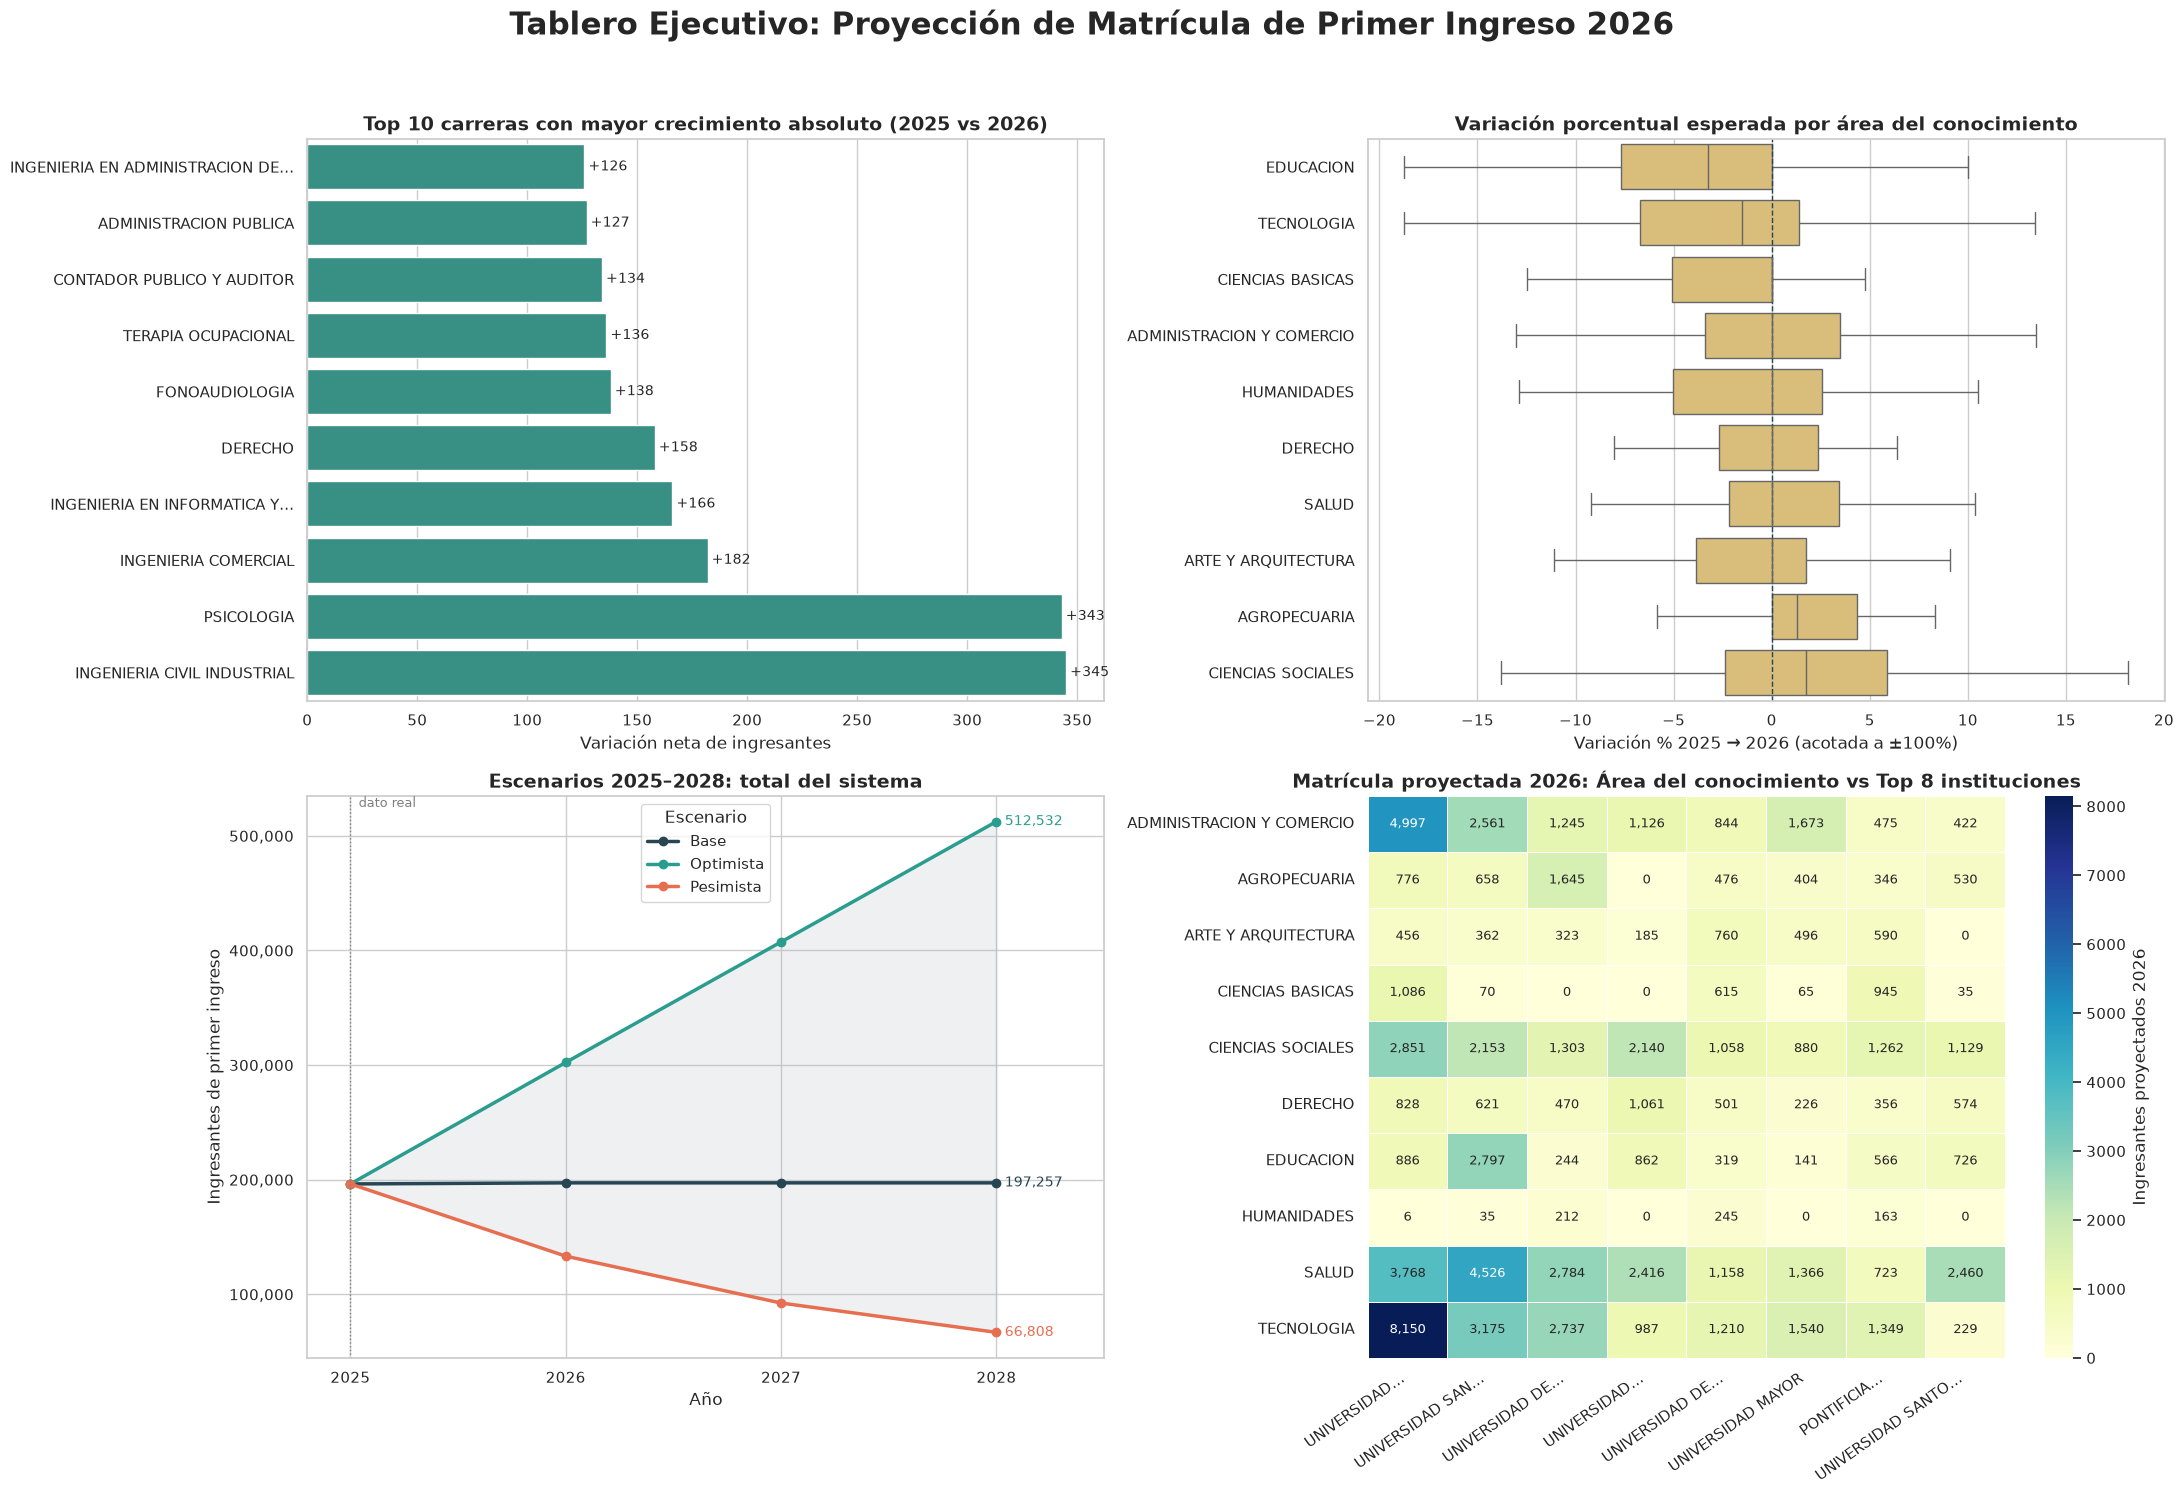

In [28]:

import gc
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
CARPETA_GRAFICOS = BASE_DIR / "graficos_diagnostico"
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)

RUTA_AGRUPADAS = CARPETA_SALIDA / "proyecciones_2026_agrupadas.parquet"
RUTA_ESCENARIOS = CARPETA_SALIDA / "proyecciones_escenarios_2026_2028.parquet"
RUTA_TABLERO = CARPETA_GRAFICOS / "tablero_proyecciones_2026.png"


def acortar(texto, ancho=32):
    """Recorta etiquetas largas para que quepan en los ejes."""
    return textwrap.shorten(str(texto), width=ancho, placeholder="…")


print("=== BLOQUE 22 ===")
try:
    sns.set_theme(style="whitegrid", context="notebook")

    agr = pd.read_parquet(RUTA_AGRUPADAS)
    esc = pd.read_parquet(RUTA_ESCENARIOS)

    fig, axes = plt.subplots(2, 2, figsize=(22, 15))
    fig.suptitle(
        "Tablero Ejecutivo: Proyección de Matrícula de Primer Ingreso 2026",
        fontsize=22, fontweight="bold", y=0.995,
    )

    # --- Gráfico 1: Top 10 carreras por crecimiento absoluto ---
    ax = axes[0, 0]
    top_carr = (
        agr.groupby("carrera_agrupada", observed=True)["variacion_neta"]
        .sum()
        .nlargest(10)
        .sort_values()
        .reset_index()
    )
    top_carr["etiqueta"] = top_carr["carrera_agrupada"].map(lambda t: acortar(t, 38))
    sns.barplot(data=top_carr, y="etiqueta", x="variacion_neta", color="#2a9d8f", ax=ax)
    for i, v in enumerate(top_carr["variacion_neta"]):
        ax.text(v, i, f" +{v:,.0f}", va="center", fontsize=10)
    ax.set_title("Top 10 carreras con mayor crecimiento absoluto (2025 vs 2026)", fontsize=14, fontweight="bold")
    ax.set_xlabel("Variación neta de ingresantes")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

    # --- Gráfico 2: Distribución de la variación % por área ---
    ax = axes[0, 1]
    dist = agr[(agr["matricula_real_2025_total"] >= 10) & agr["variacion_pct"].notna()].copy()
    dist["variacion_pct"] = dist["variacion_pct"].clip(-100, 100)
    orden = dist.groupby("area_conocimiento_limpio")["variacion_pct"].median().sort_values().index
    dist["area"] = dist["area_conocimiento_limpio"].map(lambda t: acortar(t, 30))
    orden_cortas = [acortar(a, 30) for a in orden]
    sns.boxplot(
        data=dist, x="variacion_pct", y="area", order=orden_cortas,
        color="#e9c46a", showfliers=False, ax=ax,
    )
    ax.axvline(0, color="#264653", linestyle="--", linewidth=1)
    ax.set_title("Variación porcentual esperada por área del conocimiento", fontsize=14, fontweight="bold")
    ax.set_xlabel("Variación % 2025 → 2026 (acotada a ±100%)")
    ax.set_ylabel("")

    # --- Gráfico 3: Evolución de escenarios a nivel sistema ---
    ax = axes[1, 0]
    sistema = (
        esc.groupby(["anio", "escenario"], observed=True)["matricula_proyectada"].sum().reset_index()
    )
    colores = {"Base": "#264653", "Optimista": "#2a9d8f", "Pesimista": "#e76f51"}
    for nombre, color in colores.items():
        d = sistema[sistema["escenario"] == nombre].sort_values("anio")
        ax.plot(d["anio"], d["matricula_proyectada"], marker="o", linewidth=2.5, color=color, label=nombre)
        ax.annotate(
            f"{d['matricula_proyectada'].iloc[-1]:,.0f}",
            (d["anio"].iloc[-1], d["matricula_proyectada"].iloc[-1]),
            textcoords="offset points", xytext=(6, 0), fontsize=10, color=color, va="center",
        )
    piv = sistema.pivot(index="anio", columns="escenario", values="matricula_proyectada")
    ax.fill_between(piv.index, piv["Pesimista"], piv["Optimista"], color="#adb5bd", alpha=0.2)
    ax.axvline(2025, color="gray", linestyle=":", linewidth=1)
    ax.text(2025.02, ax.get_ylim()[1], " dato real", fontsize=9, color="gray", va="top")
    ax.set_xticks(sorted(sistema["anio"].unique()))
    ax.set_xlim(2024.8, 2028.5)
    ax.set_title("Escenarios 2025–2028: total del sistema", fontsize=14, fontweight="bold")
    ax.set_xlabel("Año")
    ax.set_ylabel("Ingresantes de primer ingreso")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(title="Escenario")

    # --- Gráfico 4: Heatmap Área vs Top 8 instituciones ---
    ax = axes[1, 1]
    top_inst = (
        agr.groupby("nomb_inst_estandarizado", observed=True)["prediccion_2026_total"].sum().nlargest(8).index
    )
    mat = (
        agr[agr["nomb_inst_estandarizado"].isin(top_inst)]
        .pivot_table(
            index="area_conocimiento_limpio", columns="nomb_inst_estandarizado",
            values="prediccion_2026_total", aggfunc="sum", fill_value=0, observed=True,
        )
        .reindex(columns=list(top_inst))
    )
    mat.index = [acortar(i, 28) for i in mat.index]
    mat.columns = [acortar(c, 18) for c in mat.columns]
    sns.heatmap(
        mat, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=0.5,
        cbar_kws={"label": "Ingresantes proyectados 2026"}, annot_kws={"fontsize": 9}, ax=ax,
    )
    ax.set_title("Matrícula proyectada 2026: Área del conocimiento vs Top 8 instituciones", fontsize=14, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(RUTA_TABLERO, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Tablero guardado en: {RUTA_TABLERO}")
    plt.show()
    plt.close(fig)

    del agr, esc, sistema, mat, dist
    gc.collect()
except Exception as e:
    print(f"Error en el Bloque 22: {type(e).__name__}: {e}")

# Bloque 23: #

Motor de consultas estratégicas con DuckDB: ejecuta SQL directamente sobre los Parquet (sin cargarlos completos en pandas) y muestra tres DataFrames en consola.
1. Top 5 instituciones con mayor caída proyectada de matrícula en 2026 (solo instituciones con variación neta negativa).
2. Top 10 carreras agrupadas con mayor volatilidad entre escenarios, medida en el horizonte 2028 (rango Optimista - Pesimista y desviación estándar entre los 3 escenarios).
3. Total de ingresantes por año (2025-2028) según cada escenario.


In [29]:

import gc
from pathlib import Path

import duckdb
import pandas as pd

BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
RUTA_AGRUPADAS = CARPETA_SALIDA / "proyecciones_2026_agrupadas.parquet"
RUTA_ESCENARIOS = CARPETA_SALIDA / "proyecciones_escenarios_2026_2028.parquet"

# as_posix() evita problemas con las barras invertidas de Windows dentro del SQL
P_AGR = RUTA_AGRUPADAS.as_posix()
P_ESC = RUTA_ESCENARIOS.as_posix()

print("=== BLOQUE 23 ===")
try:
    con = duckdb.connect()
    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", 20)

    # --- Consulta 1: instituciones con mayor caída proyectada 2026 ---
    q1 = f"""
        SELECT
            nomb_inst_estandarizado AS institucion,
            CAST(SUM(matricula_real_2025_total) AS BIGINT) AS real_2025,
            CAST(SUM(prediccion_2026_total) AS BIGINT) AS proyeccion_2026,
            CAST(SUM(variacion_neta) AS BIGINT) AS variacion_neta,
            ROUND(100.0 * SUM(variacion_neta) / NULLIF(SUM(matricula_real_2025_total), 0), 2) AS variacion_pct
        FROM read_parquet('{P_AGR}')
        GROUP BY 1
        HAVING SUM(variacion_neta) < 0
        ORDER BY variacion_neta ASC
        LIMIT 5
    """
    df_q1 = con.execute(q1).df()
    print("\n--- 1. Top 5 instituciones con mayor caída proyectada en 2026 ---")
    if df_q1.empty:
        print("Ninguna institución presenta caída neta proyectada para 2026.")
    else:
        print(df_q1.to_string(index=False))

    # --- Consulta 2: carreras con mayor volatilidad entre escenarios (2028) ---
    q2 = f"""
        WITH por_carrera AS (
            SELECT carrera_agrupada, escenario, SUM(matricula_proyectada) AS total
            FROM read_parquet('{P_ESC}')
            WHERE anio = 2028
            GROUP BY 1, 2
        )
        SELECT
            carrera_agrupada,
            CAST(SUM(CASE WHEN escenario = 'Base' THEN total END) AS BIGINT) AS base_2028,
            CAST(SUM(CASE WHEN escenario = 'Optimista' THEN total END) AS BIGINT) AS optimista_2028,
            CAST(SUM(CASE WHEN escenario = 'Pesimista' THEN total END) AS BIGINT) AS pesimista_2028,
            CAST(SUM(CASE WHEN escenario = 'Optimista' THEN total END)
               - SUM(CASE WHEN escenario = 'Pesimista' THEN total END) AS BIGINT) AS rango_escenarios,
            ROUND(STDDEV_SAMP(total), 1) AS desv_est_escenarios
        FROM por_carrera
        GROUP BY 1
        ORDER BY rango_escenarios DESC
        LIMIT 10
    """
    df_q2 = con.execute(q2).df()
    print("\n--- 2. Top 10 carreras agrupadas con mayor volatilidad entre escenarios (2028) ---")
    print(df_q2.to_string(index=False))

    # --- Consulta 3: total por año y escenario ---
    q3 = f"""
        SELECT anio, escenario, CAST(SUM(matricula_proyectada) AS BIGINT) AS total_ingresantes
        FROM read_parquet('{P_ESC}')
        GROUP BY 1, 2
        ORDER BY 1, 2
    """
    df_q3 = con.execute(q3).df()
    df_q3_pivot = (
        df_q3.pivot(index="anio", columns="escenario", values="total_ingresantes")
        [["Base", "Optimista", "Pesimista"]]
    )
    print("\n--- 3. Total de primer ingreso proyectado por año y escenario (2025–2028) ---")
    print(df_q3_pivot.to_string(float_format=lambda x: f"{x:,.0f}"))

    con.close()
    del df_q1, df_q2, df_q3
    gc.collect()
except Exception as e:
    print(f"Error en el Bloque 23: {type(e).__name__}: {e}")

=== BLOQUE 23 ===

--- 1. Top 5 instituciones con mayor caída proyectada en 2026 ---
                             institucion  real_2025  proyeccion_2026  variacion_neta  variacion_pct
                UNIVERSIDAD DE ACONCAGUA       1845             1636            -209         -11.33
                 UNIVERSIDAD DEL BIO-BIO       2700             2509            -191          -7.07
UNIVERSIDAD TECNICA FEDERICO SANTA MARIA       4084             3894            -190          -4.65
                    UNIVERSIDAD DE CHILE       7374             7186            -188          -2.55
                 UNIVERSIDAD ARTURO PRAT       4268             4118            -150          -3.51

--- 2. Top 10 carreras agrupadas con mayor volatilidad entre escenarios (2028) ---
                        carrera_agrupada  base_2028  optimista_2028  pesimista_2028  rango_escenarios  desv_est_escenarios
                    INGENIERIA COMERCIAL      13285           32251            4265             27986       

# Bloque 24: #

Exporta un reporte ejecutivo consolidado en Excel (`Reporte_Ejecutivo_Matricula_2026.xlsx`, en la raíz del proyecto) con tres hojas:
- `Resumen_Sistema`: KPIs globales (matrícula real 2025, proyección 2026, variación neta y %, carreras agrupadas y programas activos, instituciones).
- `Proyección_Carreras`: tabla del Bloque 20 (carrera agrupada x institución).
- `Escenarios_2026_2028`: total del sistema por escenario y año, con variación absoluta y porcentual respecto a 2025 (Bloque 21).
Usa pandas + openpyxl, con encabezados formateados, filtros, paneles congelados y formatos numéricos.


In [30]:

import gc
from pathlib import Path

import pandas as pd
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
RUTA_AGRUPADAS = CARPETA_SALIDA / "proyecciones_2026_agrupadas.parquet"
RUTA_ESCENARIOS = CARPETA_SALIDA / "proyecciones_escenarios_2026_2028.parquet"
RUTA_EXCEL = BASE_DIR / "Reporte_Ejecutivo_Matricula_2026.xlsx"

COLOR_ENCABEZADO = PatternFill("solid", start_color="1F4E78", end_color="1F4E78")


def formatear_hoja(ws, formatos=None, ancho_max=55):
    """Encabezado destacado, filtros, panel congelado, anchos y formatos por columna."""
    formatos = formatos or {}
    for celda in ws[1]:
        celda.font = Font(bold=True, color="FFFFFF")
        celda.fill = COLOR_ENCABEZADO
        celda.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions

    for idx, col in enumerate(ws.columns, start=1):
        letra = get_column_letter(idx)
        nombre = ws.cell(row=1, column=idx).value
        largo = max(len(str(c.value)) if c.value is not None else 0 for c in col)
        ws.column_dimensions[letra].width = min(max(largo + 2, 12), ancho_max)
        if nombre in formatos:
            for celda in col[1:]:
                celda.number_format = formatos[nombre]


print("=== BLOQUE 24 ===")
try:
    agr = pd.read_parquet(RUTA_AGRUPADAS)
    esc = pd.read_parquet(RUTA_ESCENARIOS)

    # --- Hoja 1: KPIs globales ---
    total_25 = int(agr["matricula_real_2025_total"].sum())
    total_26 = int(agr["prediccion_2026_total"].sum())
    neta = total_26 - total_25
    kpis = pd.DataFrame(
        {
            "Indicador": [
                "Matrícula real de primer ingreso 2025",
                "Matrícula proyectada de primer ingreso 2026",
                "Variación neta 2025-2026",
                "Variación porcentual 2025-2026 (%)",
                "Total de carreras agrupadas activas",
                "Total de programas activos",
                "Instituciones consideradas",
            ],
            "Valor": [
                total_25,
                total_26,
                neta,
                round(neta / total_25 * 100, 2) if total_25 else None,
                int(agr["carrera_agrupada"].nunique()),
                int(agr["cantidad_programas_activos"].sum()),
                int(agr["nomb_inst_estandarizado"].nunique()),
            ],
        }
    )

    # --- Hoja 3: resumen de escenarios por año ---
    resumen_esc = (
        esc.groupby(["escenario", "anio"], observed=True)["matricula_proyectada"]
        .sum()
        .reset_index(name="matricula_total")
    )
    base_2025 = resumen_esc.loc[resumen_esc["anio"] == 2025].set_index("escenario")["matricula_total"]
    resumen_esc["variacion_vs_2025"] = resumen_esc["matricula_total"] - resumen_esc["escenario"].map(base_2025)
    resumen_esc["variacion_pct_vs_2025"] = (
        resumen_esc["variacion_vs_2025"] / resumen_esc["escenario"].map(base_2025) * 100
    ).round(2)
    orden_esc = {"Base": 0, "Optimista": 1, "Pesimista": 2}
    resumen_esc = resumen_esc.sort_values(
        ["escenario", "anio"], key=lambda s: s.map(orden_esc) if s.name == "escenario" else s
    )

    # --- Exportación ---
    with pd.ExcelWriter(RUTA_EXCEL, engine="openpyxl") as writer:
        kpis.to_excel(writer, sheet_name="Resumen_Sistema", index=False)
        agr.to_excel(writer, sheet_name="Proyección_Carreras", index=False)
        resumen_esc.to_excel(writer, sheet_name="Escenarios_2026_2028", index=False)

        formatear_hoja(writer.sheets["Resumen_Sistema"])
        ws_kpi = writer.sheets["Resumen_Sistema"]
        for fila in range(2, ws_kpi.max_row + 1):
            indicador = ws_kpi.cell(row=fila, column=1).value
            ws_kpi.cell(row=fila, column=2).number_format = "0.00" if "porcentual" in indicador else "#,##0"
        ws_kpi.column_dimensions["A"].width = 50
        ws_kpi.column_dimensions["B"].width = 18

        formatear_hoja(
            writer.sheets["Proyección_Carreras"],
            {
                "matricula_real_2025_total": "#,##0",
                "prediccion_2026_total": "#,##0",
                "variacion_neta": "#,##0;[Red]-#,##0",
                "variacion_pct": "0.00",
                "cantidad_programas_activos": "#,##0",
            },
        )
        formatear_hoja(
            writer.sheets["Escenarios_2026_2028"],
            {
                "matricula_total": "#,##0",
                "variacion_vs_2025": "#,##0;[Red]-#,##0",
                "variacion_pct_vs_2025": "0.00",
            },
        )

    print(f"Reporte exportado: {RUTA_EXCEL}")
    print(f"   ├─ Resumen_Sistema: {len(kpis)} indicadores")
    print(f"   ├─ Proyección_Carreras: {len(agr):,} filas")
    print(f"   └─ Escenarios_2026_2028: {len(resumen_esc)} filas")

    del agr, esc, kpis, resumen_esc
    gc.collect()
except PermissionError:
    print(f"No se pudo escribir '{RUTA_EXCEL.name}': ciérralo en Excel y vuelve a ejecutar.")
except Exception as e:
    print(f"Error en el Bloque 24: {type(e).__name__}: {e}")

=== BLOQUE 24 ===
Reporte exportado: /home/leandro/Escritorio/Carreras/Reporte_Ejecutivo_Matricula_2026.xlsx
   ├─ Resumen_Sistema: 7 indicadores
   ├─ Proyección_Carreras: 2,116 filas
   └─ Escenarios_2026_2028: 12 filas


# Bloque 25: Configuración de la fase final

Importa las dependencias y define rutas para leer la base histórica provisional y producir la base definitiva, el diccionario de datos y el tablero de tendencias. El IPC es opcional; si existe, debe contener cat_periodo e ipc.


In [1]:
import gc
import json
from pathlib import Path
from typing import Optional

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

BASE_DIR = Path.cwd()
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"
RUTA_ENTRADA = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
RUTA_FINAL = CARPETA_SALIDA / "base_historica_2007_2025_definitiva.parquet"
RUTA_DICCIONARIO = CARPETA_SALIDA / "diccionario_base_definitiva.json"
RUTA_IPC = CARPETA_SALIDA / "ipc_anual.csv"  # Opcional: columnas cat_periodo, ipc
RUTA_TABLERO = CARPETA_SALIDA / "tablero_tendencias_2007_2025.png"

print(f"Base de entrada: {RUTA_ENTRADA}")
print(f"Base definitiva: {RUTA_FINAL}")
print(f"IPC disponible: {RUTA_IPC.is_file()}")


Base de entrada: /home/leandro/Escritorio/Carreras/resultados_parquet/base_historica_2007_2025_provisional.parquet
Base definitiva: /home/leandro/Escritorio/Carreras/resultados_parquet/base_historica_2007_2025_definitiva.parquet
IPC disponible: False


# Bloque 26: Utilidad para completar esquemas antiguos

Define una función auxiliar que agrega columnas opcionales faltantes con tipos estables. Esto permite que la fase final procese resúmenes antiguos sin asumir que todas las columnas fueron creadas en la misma versión del pipeline.


In [2]:
def _asegurar(df: pd.DataFrame, columna: str, dtype: str = "string") -> None:
    """Crea columnas opcionales con dtype estable para tolerar esquemas antiguos."""
    if columna not in df:
        df[columna] = pd.Series(pd.NA, index=df.index, dtype=dtype)


# Bloque 27: Saneamiento de conteos, duración y arancel

Crea la función de saneamiento conservador. Prioriza el conteo corregido explícito, excluye registros que sigan pendientes, conserva trazabilidad mediante banderas de imputación y calcula arancel real únicamente cuando se proporciona un IPC válido. Los agregados por programa-año no permiten validar trayectorias MRUN individuales.


In [3]:
def sanear_base_historica(
    df_historico: pd.DataFrame,
    ipc: Optional[pd.DataFrame] = None,
) -> pd.DataFrame:
    """Sanea agregados programa-año y crea `nuevos_ingresados_definitivo`.

    Admisión: utiliza `ingresantes_corregidos` cuando existe (salida del
    Bloque 9 existente), y si no, los ingresantes identificados solo cuando el
    estado no requiere revisión. Los registros pendientes no se aceptan sin
    evidencia MRUN individual. Duración/arancel: imputación por grupo con
    respaldo global, conservando los valores originales y banderas de imputación.
    """
    try:
        df = df_historico.copy()
        for col in ["codigo_unico", "nomb_carrera", "area_carrera_generica",
                    "nomb_inst", "area_conocimiento", "region_sede",
                    "tipo_inst_2", "estado_conteo", "estado_conteo_corregido"]:
            _asegurar(df, col)
        if "cat_periodo" not in df:
            raise ValueError("Falta columna requerida: cat_periodo")
        df["cat_periodo"] = pd.to_numeric(df["cat_periodo"], errors="coerce").astype("Int64")

        for col in ["dur_total_carr_numerico", "valor_arancel_numerico",
                    "ingresantes_identificados", "ingresantes_corregidos",
                    "registros_ingreso_por_revisar", "registros_sin_mrun"]:
            if col not in df:
                candidato = col.removesuffix("_numerico")
                _asegurar(df, col, "Float64")
                if candidato in df:
                    df[col] = pd.to_numeric(df[candidato], errors="coerce").astype("Float64")
                else:
                    df[col] = pd.Series(pd.NA, index=df.index, dtype="Float64")

        # Reconciliación conservadora. El contador de pendientes agregado no
        # permite comprobar continuidad de una persona; solo se incorpora si
        # el archivo ya trae la corrección auditada y explícita del Bloque 9.
        base_ing = df["ingresantes_corregidos"].combine_first(df["ingresantes_identificados"])
        estado = df["estado_conteo_corregido"].combine_first(df["estado_conteo"]).fillna("")
        es_pendiente = estado.str.contains("Pendiente|revisar", case=False, regex=True, na=False)
        df["nuevos_ingresados_definitivo"] = pd.to_numeric(base_ing, errors="coerce").where(~es_pendiente).astype("Float64")
        # Si existía la variable provisional válida, utilizarla cuando la anterior quedó nula.
        if "nuevos_ingresados_provisional" in df:
            df["nuevos_ingresados_definitivo"] = df["nuevos_ingresados_definitivo"].combine_first(
                pd.to_numeric(df["nuevos_ingresados_provisional"], errors="coerce").astype("Float64")
            )

        # Duración normativa en semestres [4, 16]. Primero se usa el valor
        # numérico diagnosticado y luego se intenta parsear el campo original.
        if "dur_total_carr" in df:
            df["dur_total_carr_numerico"] = df["dur_total_carr_numerico"].combine_first(
                pd.to_numeric(df["dur_total_carr"], errors="coerce").astype("Float64")
            )
        dur = df["dur_total_carr_numerico"]
        df["duracion_imputada"] = (dur.isna() | dur.lt(4) | dur.gt(16)).fillna(True)
        dur_valid = dur.where(dur.between(4, 16))
        grupo_dur = "area_carrera_generica" if dur_valid.groupby(df["area_carrera_generica"]).count().sum() else "nomb_carrera"
        mediana_dur = dur_valid.groupby(df[grupo_dur], dropna=False).transform("median")
        mediana_dur = mediana_dur.fillna(dur_valid.median())
        df["dur_total_carr_definitiva"] = dur.where(dur.between(4, 16), mediana_dur).astype("Float64")

        # Arancel nulo/cero: mediana carrera-institución, luego carrera, luego global.
        if "valor_arancel" in df:
            df["valor_arancel_numerico"] = df["valor_arancel_numerico"].combine_first(
                pd.to_numeric(df["valor_arancel"], errors="coerce").astype("Float64")
            )
        arancel = df["valor_arancel_numerico"]
        valido = arancel.where(arancel.gt(0))
        grupo_ci = df["nomb_carrera"].fillna("") + "|" + df["nomb_inst"].fillna("")
        med_ci = valido.groupby(grupo_ci).transform("median")
        med_c = valido.groupby(df["nomb_carrera"], dropna=False).transform("median")
        imputado = med_ci.fillna(med_c).fillna(valido.median())
        df["arancel_imputado"] = (arancel.isna() | arancel.le(0)).fillna(True)
        df["valor_arancel_definitivo"] = arancel.where(arancel.gt(0), imputado).astype("Float64")

        # El importe real solo se calcula cuando se proporciona IPC válido.
        df["valor_arancel_real"] = pd.Series(pd.NA, index=df.index, dtype="Float64")
        if ipc is not None and not ipc.empty:
            req = {"cat_periodo", "ipc"}
            if not req.issubset(ipc.columns):
                raise ValueError("IPC debe tener columnas cat_periodo e ipc")
            tabla = ipc[["cat_periodo", "ipc"]].copy()
            tabla["cat_periodo"] = pd.to_numeric(tabla["cat_periodo"], errors="coerce").astype("Int64")
            tabla["ipc"] = pd.to_numeric(tabla["ipc"], errors="coerce")
            tabla = tabla.dropna().drop_duplicates("cat_periodo").set_index("cat_periodo")["ipc"]
            anio_base = int(tabla.index.max())
            factor = tabla.get(anio_base) / tabla
            factores = df["cat_periodo"].map(factor)
            df["valor_arancel_real"] = (df["valor_arancel_definitivo"] * factores).astype("Float64")
            df.attrs["ipc_anio_base"] = anio_base

        # Dtypes de extensión para columnas clave.
        for col in ["nomb_carrera", "nomb_inst", "area_conocimiento", "region_sede"]:
            df[col] = df[col].astype("string")
        print(f"Saneamiento completado: {len(df):,} filas; {int(df['nuevos_ingresados_definitivo'].notna().sum()):,} conteos válidos.")
        gc.collect()
        return df
    except Exception as exc:
        print(f"Error en sanear_base_historica: {exc}")
        raise


# Bloque 28: Armonización y ciclo de vida de programas

Armoniza etiquetas de carrera, institución y áreas por código único. Calcula año de apertura, último año observado, años presentes, estado (activa, emergente o discontinuada) y marca vacíos internos sin inventar registros anuales.


In [4]:
def armonizar_programas(df: pd.DataFrame) -> pd.DataFrame:
    """Armoniza etiquetas por código y calcula apertura, cierre y ciclo de vida."""
    try:
        out = df.copy()
        out = out.sort_values(["codigo_unico", "cat_periodo"], na_position="last")
        for col in ["nomb_carrera", "nomb_inst", "area_conocimiento", "area_carrera_generica"]:
            if col in out:
                out[f"{col}_armonizado"] = out.groupby("codigo_unico", dropna=False)[col].transform(
                    lambda s: s.dropna().mode().iloc[0] if not s.dropna().mode().empty else pd.NA
                ).astype("string")
        stats = out.groupby("codigo_unico", dropna=False).agg(
            anio_apertura=("cat_periodo", "min"),
            ultimo_anio_observado=("cat_periodo", "max"),
            anios_observados=("cat_periodo", "nunique"),
        )
        stats["anio_cierre_o_pausa"] = stats["ultimo_anio_observado"].where(stats["ultimo_anio_observado"].lt(2025), pd.NA).astype("Int64")
        stats["estado_carrera"] = "Activa"
        stats.loc[stats["anio_apertura"].ge(2020), "estado_carrera"] = "Emergente"
        stats.loc[stats["ultimo_anio_observado"].lt(2025), "estado_carrera"] = "Discontinuada"
        # Vacíos internos: marca discontinuidad/pausa observacional sin inventar filas anuales.
        gaps = out.groupby("codigo_unico")["cat_periodo"].apply(
            lambda s: (int(s.max()) - int(s.min()) + 1) > s.nunique() if s.notna().any() else False
        )
        stats["tiene_vacios_matricula"] = gaps
        out = out.merge(stats.reset_index(), on="codigo_unico", how="left", validate="many_to_one")
        out["anio_apertura"] = out["anio_apertura"].astype("Int64")
        out["anios_observados"] = out["anios_observados"].astype("Int64")
        print(f"Armonización completada: {out['codigo_unico'].nunique():,} códigos de programa.")
        gc.collect()
        return out
    except Exception as exc:
        print(f"Error en armonizar_programas: {exc}")
        raise


# Bloque 29: Exportación de base definitiva y diccionario

Guarda la tabla saneada en Parquet comprimido y exporta un diccionario JSON con número de filas, período, tipos y definiciones de variables derivadas. Las banderas permiten distinguir datos imputados de datos originales.


In [5]:
def exportar_dataset(df: pd.DataFrame, destino: Path = RUTA_FINAL) -> Path:
    """Exporta Parquet comprimido y diccionario con esquema/tipos."""
    try:
        destino.parent.mkdir(parents=True, exist_ok=True)
        df.to_parquet(destino, index=False, compression="snappy")
        diccionario = {
            "archivo": destino.name,
            "filas": int(len(df)),
            "periodo": [2007, 2025],
            "tipos": {str(c): str(t) for c, t in df.dtypes.items()},
            "variables_derivadas": {
                "nuevos_ingresados_definitivo": "Conteo conservador de primer ingreso; requiere revisión donde hay incidencia no auditada a nivel MRUN.",
                "dur_total_carr_definitiva": "Duración en semestres; fuera de [4,16] imputada por mediana de área/carrera.",
                "valor_arancel_definitivo": "Arancel nominal; ceros/nulos imputados por carrera-institución y respaldos.",
                "valor_arancel_real": "Arancel deflactado si se provee IPC anual; NA si no.",
                "anio_apertura": "Primer año observado para codigo_unico.",
                "anio_cierre_o_pausa": "Último año observado si anterior a 2025.",
                "estado_carrera": "Emergente (apertura >=2020), Discontinuada (sin observación 2025) o Activa.",
            },
        }
        RUTA_DICCIONARIO.write_text(json.dumps(diccionario, ensure_ascii=False, indent=2), encoding="utf-8")
        print(f"Dataset definitivo: {destino}\nDiccionario: {RUTA_DICCIONARIO}")
        return destino
    except Exception as exc:
        print(f"Error al exportar dataset/metadatos: {exc}")
        raise


# Bloque 30: KPIs analíticos mediante DuckDB

Consulta el Parquet definitivo para generar tres tablas: programas con mayor crecimiento 2007–2025, brecha de arancel nominal/real por tipo de institución y durabilidad observada por área. Si no hay IPC, el KPI de arancel real aparecerá sin valores.


In [7]:
def generar_kpis(ruta: Path = RUTA_FINAL) -> dict[str, pd.DataFrame]:
    """Ejecuta consultas DuckDB y devuelve los tres DataFrames ejecutivos."""
    try:
        con = duckdb.connect(database=":memory:")
        p = str(ruta.resolve()).replace("'", "''")
        con.execute(f"CREATE VIEW base AS SELECT * FROM read_parquet('{p}')")
        consultas = {
            "top_crecimiento": """
                WITH x AS (SELECT codigo_unico, nomb_carrera, area_conocimiento,
                    SUM(CASE WHEN cat_periodo=2007 THEN nuevos_ingresados_definitivo ELSE 0 END) y0,
                    SUM(CASE WHEN cat_periodo=2025 THEN nuevos_ingresados_definitivo ELSE 0 END) y1
                    FROM base GROUP BY ALL)
                SELECT *, 100.0*(y1-y0)/NULLIF(y0,0) crecimiento_pct FROM x
                WHERE y0>0 AND y1 IS NOT NULL ORDER BY crecimiento_pct DESC LIMIT 15
            """,
            "brecha_aranceles": """
                SELECT cat_periodo,
                    CASE WHEN lower(coalesce(tipo_inst_2,'')) LIKE '%public%' THEN 'Pública' ELSE 'Privada/otra' END tipo_institucion,
                    AVG(valor_arancel_real) arancel_real_promedio,
                    AVG(valor_arancel_definitivo) arancel_nominal_promedio
                FROM base GROUP BY 1,2 ORDER BY 1,2
            """,
            "retencion_area": """
                WITH programa AS (
                    SELECT codigo_unico, COALESCE(area_carrera_generica, area_conocimiento, 'Sin área') area,
                        MIN(cat_periodo) apertura, MAX(cat_periodo) ultimo,
                        COUNT(DISTINCT cat_periodo) anios,
                        COUNT(DISTINCT cat_periodo) FILTER (WHERE nuevos_ingresados_definitivo>0) anios_con_ingreso
                    FROM base GROUP BY 1,2)
                SELECT area, COUNT(*) programas,
                    AVG(anios_con_ingreso / NULLIF(ultimo-apertura+1,0)) tasa_retencion_observada,
                    AVG(ultimo-apertura+1) durabilidad_anios_promedio
                FROM programa GROUP BY 1 ORDER BY programas DESC
            """,
        }
        resultados = {nombre: con.execute(sql).df() for nombre, sql in consultas.items()}
        for nombre, frame in resultados.items():
            print(f"\nKPI {nombre}:\n{frame.to_string(index=False)}")
        con.close()
        return resultados
    except Exception as exc:
        print(f"Error al generar KPIs DuckDB: {exc}")
        raise


# Bloque 31: Tablero de tendencias longitudinales

Produce un PNG con tendencias de primer ingreso por área, distribución de duración saneada, arancel real cuando existe IPC, cobertura de programas por región y año, y composición del ciclo de vida de los programas.


In [8]:
def generar_tablero(df: pd.DataFrame, destino: Path = RUTA_TABLERO) -> Path:
    """Guarda tablero de cinco paneles con las columnas disponibles."""
    try:
        sns.set_theme(style="whitegrid")
        fig, axes = plt.subplots(2, 3, figsize=(19, 11))
        a = axes.flat
        area = "area_conocimiento" if "area_conocimiento" in df else "area_carrera_generica"
        serie = df.groupby(["cat_periodo", area], dropna=False)["nuevos_ingresados_definitivo"].sum(min_count=1).reset_index()
        top_areas = serie.groupby(area)["nuevos_ingresados_definitivo"].sum().nlargest(8).index
        sns.lineplot(data=serie[serie[area].isin(top_areas)], x="cat_periodo", y="nuevos_ingresados_definitivo", hue=area, ax=a[0])
        a[0].set_title("Primer ingreso por área")
        sns.boxplot(data=df, x="dur_total_carr_definitiva", ax=a[1], color="#6baed6")
        a[1].set_title("Duración saneada (semestres)")
        if df["valor_arancel_real"].notna().any():
            sns.lineplot(data=df.groupby("cat_periodo", as_index=False)["valor_arancel_real"].median(), x="cat_periodo", y="valor_arancel_real", ax=a[2])
            a[2].set_title("Mediana arancel real")
        else:
            a[2].text(.5, .5, "IPC no disponible: cargar ipc_anual.csv", ha="center", va="center")
            a[2].set_title("Arancel real")
        if "region_sede" in df:
            tmp = df.groupby(["region_sede", "cat_periodo"], dropna=False)["codigo_unico"].nunique().unstack(fill_value=0)
            if not tmp.empty:
                sns.heatmap(tmp, cmap="YlGnBu", ax=a[3], cbar_kws={"label": "Programas observados"})
            a[3].set_title("Programas por región y año")
        a[4].bar(["Activa", "Discontinuada", "Emergente"], df.drop_duplicates("codigo_unico")["estado_carrera"].value_counts().reindex(["Activa", "Discontinuada", "Emergente"], fill_value=0))
        a[4].set_title("Estado del ciclo de vida")
        a[5].axis("off")
        fig.suptitle("Tendencias de matrícula de Educación Superior, Chile 2007–2025", fontsize=16)
        fig.tight_layout()
        destino.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destino, dpi=220, bbox_inches="tight")
        plt.close(fig)
        print(f"Tablero guardado: {destino}")
        return destino
    except Exception as exc:
        print(f"Error al generar tablero: {exc}")
        raise


# Bloque 32: Ejecución integrada de la fase final

Ejecuta en secuencia la lectura de la base provisional, saneamiento, armonización, exportación definitiva, cálculo de KPIs y generación del tablero. Al ejecutar esta celda se crean los archivos de salida descritos en los bloques anteriores.


In [9]:
def ejecutar_pipeline() -> pd.DataFrame:
    """Corre Bloques 9-13 usando la salida provisional existente."""
    if not RUTA_ENTRADA.is_file():
        raise FileNotFoundError(f"No se encontró la base provisional: {RUTA_ENTRADA}")
    try:
        print(f"Leyendo {RUTA_ENTRADA.name}...")
        origen = pd.read_parquet(RUTA_ENTRADA)
        ipc = pd.read_csv(RUTA_IPC) if RUTA_IPC.is_file() else None
        limpio = sanear_base_historica(origen, ipc=ipc)
        armonizado = armonizar_programas(limpio)
        exportar_dataset(armonizado)
        generar_kpis(RUTA_FINAL)
        generar_tablero(armonizado)
        del origen, limpio
        gc.collect()
        return armonizado
    except Exception as exc:
        print(f"Pipeline final detenido: {exc}")
        raise

if __name__ == "__main__":
    df_historico_definitivo = ejecutar_pipeline()


Leyendo base_historica_2007_2025_provisional.parquet...
Saneamiento completado: 92,396 filas; 60,264 conteos válidos.
Armonización completada: 14,978 códigos de programa.
Dataset definitivo: /home/leandro/Escritorio/Carreras/resultados_parquet/base_historica_2007_2025_definitiva.parquet
Diccionario: /home/leandro/Escritorio/Carreras/resultados_parquet/diccionario_base_definitiva.json

KPI top_crecimiento:
codigo_unico               nomb_carrera         area_conocimiento   y0    y1  crecimiento_pct
I13S10C6J2V1                 PSICOLOGIA         Ciencias Sociales  1.0  30.0      2900.000000
I39S6C17J1V1       MEDICINA VETERINARIA              Agropecuaria 14.0 262.0      1771.428571
 I39S6C3J1V1                    DERECHO                   Derecho  9.0 141.0      1466.666667
 I81S1C4J1V1 CONTADOR PUBLICO Y AUDITOR Administración y Comercio  4.0  30.0       650.000000
 I39S6C9J1V1          TECNOLOGIA MEDICA                     Salud 27.0 172.0       537.037037
I39S2C56J1V1        TERAPIA